In [2]:
import numpy as np
import pandas as pd
from astropy.io import fits
import os
from scipy.spatial import cKDTree
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from sklearn.cluster import KMeans

In [17]:
# Basic quantities, loading and converting to coordinates on Galactic plane

## Test 1: Mass > 1e4. Cannot work. There is only 1 point on the low side of the Perseus kink and it is so far away it's not even assigned 
## to it. Perseus can't work in this test.

## Test 2: Complete. Can work well but has issues with Perseus arm. Not enough points exist to fit the other side of the kink.
## Can be aleviated if I reduced min_point son the fitting functions (least squares and Huber loss) from 20 to 1 or 2


R0 = 8.15

df_2 = pd.read_csv('Full_test_catalogue.csv')


mask = df_2['Mass'] > 10 ** 5
#mask= df_2['M_13CO_X_Sol'] > 10 ** 4
#mask = (df_2['Mass'] / df_2['final_distance'] ** 2) > 75.7
#mask = df_2['Mass'] > 10 ** 4

df_2 = df_2[mask]

l = np.radians(df_2["x_cen"].to_numpy())
b = np.radians(df_2["y_cen"].to_numpy())
d = df_2["final_distance"].to_numpy()

X = d * np.cos(b) * np.sin(l)
Y = R0 - d * np.cos(b) * np.cos(l)

R = np.hypot(X, Y)

# Reid azimuth convention
beta = np.degrees(np.arctan2(X, Y))

df_2["X_kpc"] = X
df_2["Y_kpc"] = Y
df_2["R_kpc"] = R
df_2["beta_deg"] = beta
df_2["ln_R"] = np.log(R)

In [18]:
# Old function from Mopra_spiral_arms_Reid.py

def reid_arm(name, n=2000, extend_low=0, extend_high=0,
             params=None):

    if params is None:
        params = parameters

    bmin, bmax, bkink, Rkink, p_low, p_high = params[name]

    beta = np.linspace(
        bmin - extend_low,
        bmax + extend_high,
        n
    )

    pitch = np.where(beta <= bkink, p_low, p_high)

    R = Rkink * np.exp(
        -np.radians(beta - bkink)
        * np.tan(np.radians(pitch))
    )

    X = R * np.sin(np.radians(beta))
    Y = R * np.cos(np.radians(beta))

    original = (beta >= bmin) & (beta <= bmax)

    return {
        "beta": beta,
        "R": R,
        "X": X,
        "Y": Y,
        "original": original
    }

arm_names = ["Norma", "Sct-Cen", "Sgr-Car", "Perseus", "3-kpc"]

parameters = {
    "3-kpc":   (15, 18, 15, 3.52, -4.2, -4.2),
    "Norma":   (5, 54, 18, 4.46, -1.0, 19.5),
    "Sct-Cen": (0, 104, 23, 4.91, 14.1, 12.1),
    "Sgr-Car": (2, 97, 24, 6.04, 17.1, 1.0),
    "Local":   (-8, 34, 9, 8.26, 11.4, 11.4),
    "Perseus": (-23, 115, 40, 8.87, 10.3, 8.7),
    "Outer":   (-16, 71, 18, 12.24, 3.0, 9.4),
}

# Fill these with verified Reid (2019) width values, in kpc
arm_widths = {
    "Norma": 0.14,
    "Sct-Cen" : 0.23,
    "Sgr-Car" : 0.27,
    "Perseus" : 0.35,
    "3-kpc"   : 0.18
}


# Generate all four arms
extended_arms = {
    name: reid_arm(
        name,
        extend_low  = 130,
        extend_high =130
    )
    for name in arm_names
}

In [19]:
R0 = 8.15          # kpc
Theta0 = 236.0     # km/s

# Brand & Blitz (1993) coefficients
a1 = 1.00767
a2 = 0.0394
a3 = 0.00712

def brand_blitz(R):
    ratio = R / R0

    # Normalize so Theta(R0) = Theta0
    return Theta0 * (
        (a1 * ratio**a2 + a3) / (a1 + a3)
    )


for name, arm in extended_arms.items():

    X = np.asarray(arm["X"])
    Y = np.asarray(arm["Y"])

    # Galactocentric radius
    R = np.asarray(arm['R'])

    # Galactic longitude (degrees)
    l = np.degrees(
        np.arctan2(X, R0 - Y)
    ) % 360

    # Circular rotation velocity
    Theta = brand_blitz(R)

    # Line-of-sight velocity relative to LSR
    V_lsr = (
        Theta * R0 / R - Theta0
    ) * np.sin(np.radians(l))

    # Add results to dictionary
    arm["R"] = R
    arm["l"] = l
    arm["Theta"] = Theta
    arm["V_lsr"] = V_lsr

In [6]:
# Assigning clouds to arms using KD Tree
colours = {
    "Norma": "red",
    "Sct-Cen": "blue",
    "Sgr-Car": "purple",
    "Perseus": "black",
    "3-kpc": "orange"
}

# Catalogue coordinates
cloud_xy = df_2[["X_kpc", "Y_kpc"]].to_numpy(dtype=float)  # Collect the coordinates of each cloud on the (X,Y) Galactic plane
valid = np.isfinite(cloud_xy).all(axis=1)

# Calculate distances to each arm
for name, arm in extended_arms.items():

    arm_xy = np.column_stack([
        arm["X"],
        arm["Y"]
    ])  # Collect the points making up each arm on the Galactic plane

    tree = cKDTree(arm_xy)  # Create the KD tree

    distances = np.full(len(df_2), np.nan)

    distances[valid], _ = tree.query(cloud_xy[valid]) 
    # distances: the distance, in kpc, from each cloud to the nearest sampled point on that arm.
    # indices: the index of that nearest arm point within arm_xy.

    df_2[f"dist_{name}_kpc"] = distances

# Identify nearest arm
distance_columns = [
    f"dist_{name}_kpc" for name in arm_names
]

distance_matrix = df_2[distance_columns].to_numpy()

closest_index = np.full(len(df_2), -1, dtype=int)
closest_distance = np.full(len(df_2), np.nan)

closest_index[valid] = np.argmin(
    distance_matrix[valid], axis=1  # Find arm with lowest distance
)                                  

closest_distance[valid] = np.min(
    distance_matrix[valid], axis=1
)

df_2["nearest_arm"] = [
    arm_names[i] if i >= 0 else None
    for i in closest_index
]

df_2["arm_distance_kpc"] = closest_distance

# Apply an initial association threshold
# Clouds will not be associated if their distance is higher than this, 3 * width
n_sigma = 3.0

df_2["assigned_arm"] = "Unassigned"

for name in arm_names:

    mask = (
        (df_2["nearest_arm"] == name)
        & (df_2["arm_distance_kpc"] <= n_sigma * arm_widths[name])
    )

    df_2.loc[mask, "assigned_arm"] = name

print(df_2["assigned_arm"].value_counts())

assigned_arm
Sct-Cen       553
Sgr-Car       357
Unassigned    217
Norma         188
3-kpc         101
Perseus        74
Name: count, dtype: int64


In [7]:
# Issue discovered later: Turn azimuth to 360 degrees to avoid problems
# Preserve the original wrapped azimuths
df_2["beta_unwrapped_deg"] = df_2["beta_deg"].copy()

# Record the winding number for diagnostic purposes
df_2["beta_winding"] = np.nan

for name in arm_names:

    subset = df_2.loc[
        (df_2["assigned_arm"] == name)
        & np.isfinite(df_2["X_kpc"])
        & np.isfinite(df_2["Y_kpc"])
        & np.isfinite(df_2["beta_deg"])
    ]

    if subset.empty:
        continue

    # Original extended Reid curve
    arm = extended_arms[name]

    arm_xy = np.column_stack([
        arm["X"],
        arm["Y"]
    ])

    arm_beta = np.asarray(arm["beta"])

    # Remove any invalid arm points
    valid = (
        np.isfinite(arm_xy).all(axis=1)
        & np.isfinite(arm_beta)
    )

    arm_xy = arm_xy[valid]
    arm_beta = arm_beta[valid]

    if len(arm_beta) == 0:
        continue

    # Find nearest Reid-arm point for each cloud
    tree = cKDTree(arm_xy)

    cloud_xy = subset[["X_kpc", "Y_kpc"]].to_numpy()

    distances, indices = tree.query(cloud_xy)

    beta_nearest = arm_beta[indices]

    # Cloud's original wrapped azimuth
    beta_wrapped = subset["beta_deg"].to_numpy()

    # Find the integer winding that matches the Reid arm
    winding = np.rint(
        (beta_nearest - beta_wrapped) / 360.0
    ).astype(int)

    # Corrected cloud azimuth
    beta_unwrapped = beta_wrapped + 360.0 * winding

    # Store results
    df_2.loc[
        subset.index, "beta_unwrapped_deg"
    ] = beta_unwrapped

    df_2.loc[
        subset.index, "beta_winding"
    ] = winding

# Correct remaining negative-beta Perseus clouds
# Only if their intended branch is the positive continuation

#mask = (
#    (df_2["assigned_arm"] == "Perseus")
#    & (df_2["beta_unwrapped_deg"] < 0)
#)

#print(f"Correcting {mask.sum()} Perseus clouds")

#df_2.loc[mask, "beta_unwrapped_deg"] = (
#    df_2.loc[mask, "beta_deg"] + 360.0
#)

#df_2.loc[mask, "beta_winding"] = 1

# Replace wrapped beta with corrected beta
#df_2["beta_deg"] = df_2["beta_unwrapped_deg"].copy()

# Verify
#print(
#    "Remaining negative Perseus azimuths:",
#    (
#        (df_2["assigned_arm"] == "Perseus")
#        & (df_2["beta_deg"] < 0)
#    ).sum()
#)

In [8]:
## Add arm asssignments and distances to the dataframe

# Distances already calculated using KD-trees
distance_columns = [f"dist_{name}_kpc" for name in arm_names]

distance_matrix = df_2[distance_columns].to_numpy(dtype=float)

width_array = np.array([arm_widths[name] for name in arm_names])

# Normalize by arm width
normalized_distances = distance_matrix / width_array[None, :]

# Save normalized distances, called z
for j, name in enumerate(arm_names):
    df_2[f"z_{name}"] = normalized_distances[:, j]

# Check

valid = np.isfinite(normalized_distances).all(axis=1)

best_index = np.full(len(df_2), -1, dtype=int)
best_z = np.full(len(df_2), np.nan)

best_index[valid] = np.argmin(
    normalized_distances[valid],
    axis=1
)

best_z[valid] = np.min(
    normalized_distances[valid],
    axis=1
)

df_2["assigned_arm"] = "Unassigned"
df_2["arm_z"] = best_z

for j, name in enumerate(arm_names):
    mask = (best_index == j) & (best_z <= n_sigma)
    df_2.loc[mask, "assigned_arm"] = name

print(df_2["assigned_arm"].value_counts())

# Check

sorted_z = np.sort(normalized_distances, axis=1)

df_2["second_best_z"] = np.where(
    valid, sorted_z[:, 1], np.nan
)

df_2["arm_separation_z"] = (
    df_2["second_best_z"] - df_2["arm_z"]
)

print(
    df_2[
        ["Universal_ID", "assigned_arm",
         "arm_z", "second_best_z", "arm_separation_z"]
    ].head(10)
)
# Measure if 2 arms well approach a source. A large arm_separation means a good first choice.

assigned_arm
Sct-Cen       561
Sgr-Car       359
Unassigned    206
Norma         177
3-kpc         106
Perseus        81
Name: count, dtype: int64
    Universal_ID assigned_arm      arm_z  second_best_z  arm_separation_z
0              1   Unassigned  12.317722      18.386406          6.068684
1              2   Unassigned   7.524282      12.166083          4.641801
2              3   Unassigned   6.811894      11.848539          5.036644
3              4        3-kpc   0.898390       7.088126          6.189735
4              5      Sgr-Car   2.840847       6.724518          3.883671
5              6      Sct-Cen   2.133326       2.150268          0.016942
6              7      Sgr-Car   0.365999       6.419067          6.053068
7              8   Unassigned   3.261256       6.394053          3.132797
8              9      Sgr-Car   2.053421       7.346399          5.292978
10            11      Sgr-Car   0.989087       4.736497          3.747411


In [9]:
indices = [1385, 1759, 1765]

arm = extended_arms["Perseus"]

arm_xy = np.column_stack([arm["X"], arm["Y"]])
arm_beta = np.asarray(arm["beta"])

valid = np.isfinite(arm_xy).all(axis=1) & np.isfinite(arm_beta)

tree = cKDTree(arm_xy[valid])

cloud_xy = df_2.loc[indices, ["X_kpc", "Y_kpc"]].to_numpy()

distances, nearest_indices = tree.query(cloud_xy)

beta_nearest = arm_beta[valid][nearest_indices]
beta_wrapped = df_2.loc[indices, "beta_deg"].to_numpy()

winding = np.rint(
    (beta_nearest - beta_wrapped) / 360.0
).astype(int)

print(
    pd.DataFrame({
        "beta_wrapped": beta_wrapped,
        "beta_nearest_arm": beta_nearest,
        "winding": winding,
        "distance_kpc": distances
    }, index=indices)
)

indices = [1385, 1759, 1765]

# Assign the windings calculated in the diagnostic
df_2.loc[indices, "beta_winding"] = winding

# Update their unwrapped azimuths
df_2.loc[indices, "beta_unwrapped_deg"] = (
    df_2.loc[indices, "beta_deg"]
    + 360.0 * df_2.loc[indices, "beta_winding"]
)

# Verify the dataframe was updated
print(
    df_2.loc[
        indices,
        ["beta_deg", "beta_unwrapped_deg", "beta_winding", "arm_separation_z"]
    ]
)

b_corr = df_2.loc[df_2['Universal_ID'] == 1546]['beta_unwrapped_deg']
b_corr = b_corr.loc[1545] + 360
df_2.at[1545,'beta_unwrapped_deg'] = b_corr

      beta_wrapped  beta_nearest_arm  winding  distance_kpc
1385   -104.097836        245.000000        1      0.988417
1759   -163.160622        198.609805        1      1.020023
1765   -165.684829        196.021511        1      0.955345
        beta_deg  beta_unwrapped_deg  beta_winding  arm_separation_z
1385 -104.097836          255.902164           1.0          3.810206
1759 -163.160622          196.839378           1.0          0.529664
1765 -165.684829          194.315171           1.0          0.341069


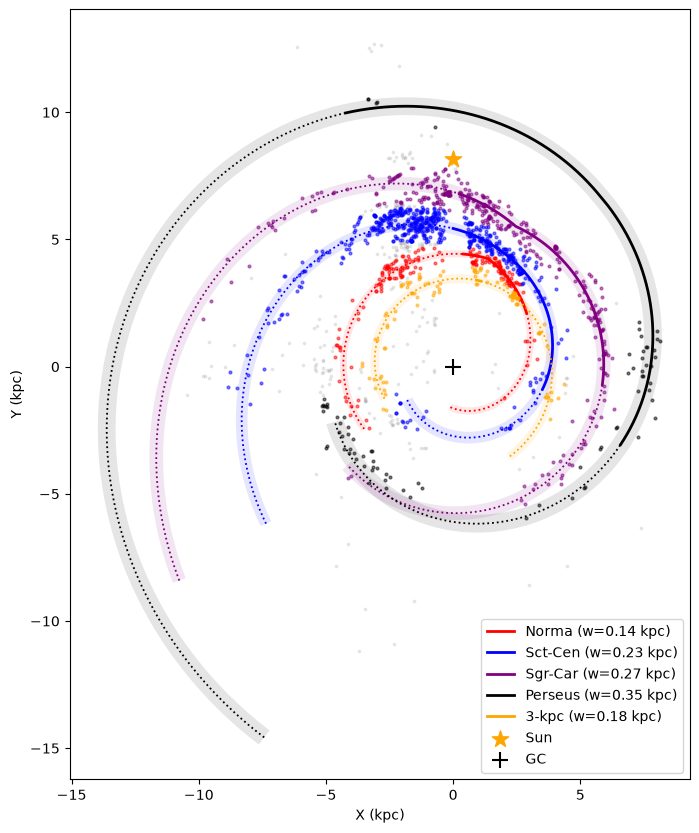

In [10]:
# Plot arms assignment ver.1

fig, ax = plt.subplots(figsize=(10, 10))

for name, arm in extended_arms.items():

    beta = arm["beta"]
    X = arm["X"]
    Y = arm["Y"]

    bmin, bmax, *_ = parameters[name]

    original = (beta >= bmin) & (beta <= bmax)
    extension_low = beta < bmin
    extension_high = beta > bmax

    # Arm width (kpc)
    w = arm_widths[name]

    # Tangent vector along the spiral
    dx = np.gradient(X)
    dy = np.gradient(Y)

    length = np.hypot(dx, dy)

    # Unit normal vector
    nx = -dy / length
    ny = dx / length

    # Boundaries at +/- one arm width
    X_upper = X + w * nx
    Y_upper = Y + w * ny

    X_lower = X - w * nx
    Y_lower = Y - w * ny

    # Fill the band between the two boundaries
    band_x = np.concatenate([X_upper, X_lower[::-1]])
    band_y = np.concatenate([Y_upper, Y_lower[::-1]])

    ax.fill(
        band_x,
        band_y,
        color=colours[name],
        alpha=0.10,
        linewidth=0,
        zorder=1
    )

    # Original arm centreline
    ax.plot(
        X[original],
        Y[original],
        color=colours[name],
        lw=2,
        ls="-",
        label=f"{name} (w={w:.2f} kpc)",
        zorder=3
    )

    # Plot extensions separately to avoid artificial connections
    for mask in [extension_low, extension_high]:

        ax.plot(
            X[mask],
            Y[mask],
            color=colours[name],
            lw=1.3,
            ls=":",
            zorder=3
        )

# Catalogue clouds, coloured by assigned arm
for name in arm_names:

    subset = df_2[df_2["assigned_arm"] == name]

    ax.scatter(
        subset["X_kpc"],
        subset["Y_kpc"],
        s=4,
        color=colours[name],
        alpha=0.5,
        rasterized=True,
        zorder=4
    )

# Unassigned clouds
unassigned = df_2[df_2["assigned_arm"] == "Unassigned"]

ax.scatter(
    unassigned["X_kpc"],
    unassigned["Y_kpc"],
    s=3,
    color="grey",
    alpha=0.15,
    rasterized=True,
    zorder=2
)

# Sun and Galactic Centre
ax.scatter(0, R0, marker="*", s=150,
           color="orange", zorder=5, label="Sun")

ax.scatter(0, 0, marker="+", s=120,
           color="black", zorder=5, label="GC")

ax.set_xlabel("X (kpc)")
ax.set_ylabel("Y (kpc)")
ax.set_aspect("equal")
ax.legend()

plt.show()

In [11]:
# Check
print(
    df_2.groupby("assigned_arm")["arm_z"]
    .agg(["count", "median", "mean"])
)

              count    median      mean
assigned_arm                           
3-kpc           106  0.944409  1.220925
Norma           177  1.088899  1.222174
Perseus          81  1.107409  1.163092
Sct-Cen         561  1.116673  1.199648
Sgr-Car         359  0.767870  0.971783
Unassigned      206  3.911632  4.723910


# Experiment one: 3-parameter fit

In [12]:
## Fit clouds to double Reid arm, with kink and 2 pitch angles

def fit_reid_arm(df, name, parameters, min_points=2):

    bmin, bmax, bkink, Rkink, p_low, p_high = parameters[name] # Looks like we are feeding Rkink, bkink into this and fit for R,b

    subset = df.loc[
        (df["assigned_arm"] == name)
        & np.isfinite(df["beta_unwrapped_deg"])
        & np.isfinite(df["R_kpc"])
        & (df["R_kpc"] > 0)
    ].copy()

    if len(subset) < min_points:
        return None

    # Azimuth relative to Reid kink, in radians
    beta = np.radians(subset["beta_unwrapped_deg"].to_numpy())
    beta_kink = np.radians(bkink)

    x = beta - beta_kink
    y = np.log(subset["R_kpc"].to_numpy())

    # Continuous piecewise-linear model, looks like with high and low we fit for under and over the kink
    x_low = np.minimum(x, 0.0)
    x_high = np.maximum(x, 0.0)

    A = np.column_stack([  ## A has the parameters for both high and low, before and after kink
        np.ones_like(x),
        x_low,
        x_high
    ])   

    # Ordinary least squares for the first experiment
    coefficients, residuals, rank, singular_values = (  ## Fitting for A containing high and low, coefficients are a, mhigh and mlow
        np.linalg.lstsq(A, y, rcond=None)
    )

    if rank < 3:
        return None

    a, m_low, m_high = coefficients

    return {
        "name": name,
        "N": len(subset),
        "Rkink_fit": np.exp(a),
        "pitch_low_fit": np.degrees(np.arctan(-m_low)),
        "pitch_high_fit": np.degrees(np.arctan(-m_high)),
        "Rkink_Reid": Rkink,
        "pitch_low_Reid": p_low,
        "pitch_high_Reid": p_high
    }


fit_results = []

for name in arm_names:

    result = fit_reid_arm(df_2, name, parameters)
    
    if result is not None:
        fit_results.append(result)

fit_table = pd.DataFrame(fit_results)

print(fit_table.round(3).to_string(index=False))

   name   N  Rkink_fit  pitch_low_fit  pitch_high_fit  Rkink_Reid  pitch_low_Reid  pitch_high_Reid
  Norma 177      4.457         -0.458          18.779        4.46            -1.0             19.5
Sct-Cen 561      4.938         14.251          10.713        4.91            14.1             12.1
Sgr-Car 359      5.940         17.156           0.235        6.04            17.1              1.0
Perseus  81      8.543         13.068           8.556        8.87            10.3              8.7
  3-kpc 106      3.657         -5.286          -2.644        3.52            -4.2             -4.2


In [13]:
fit_results

[{'name': 'Norma',
  'N': 177,
  'Rkink_fit': np.float64(4.456654781128819),
  'pitch_low_fit': np.float64(-0.45776311666441294),
  'pitch_high_fit': np.float64(18.779304655732652),
  'Rkink_Reid': 4.46,
  'pitch_low_Reid': -1.0,
  'pitch_high_Reid': 19.5},
 {'name': 'Sct-Cen',
  'N': 561,
  'Rkink_fit': np.float64(4.937600923997253),
  'pitch_low_fit': np.float64(14.250987591547393),
  'pitch_high_fit': np.float64(10.713311409129537),
  'Rkink_Reid': 4.91,
  'pitch_low_Reid': 14.1,
  'pitch_high_Reid': 12.1},
 {'name': 'Sgr-Car',
  'N': 359,
  'Rkink_fit': np.float64(5.939840896078051),
  'pitch_low_fit': np.float64(17.15551936111548),
  'pitch_high_fit': np.float64(0.23525081076186058),
  'Rkink_Reid': 6.04,
  'pitch_low_Reid': 17.1,
  'pitch_high_Reid': 1.0},
 {'name': 'Perseus',
  'N': 81,
  'Rkink_fit': np.float64(8.543184980663398),
  'pitch_low_fit': np.float64(13.068356374856544),
  'pitch_high_fit': np.float64(8.556348546475492),
  'Rkink_Reid': 8.87,
  'pitch_low_Reid': 10.3,

In [14]:
## Load fit parameters

fitted_parameters = parameters.copy()

for result in fit_results:

    name = result["name"]

    bmin, bmax, bkink, _, _, _ = parameters[name]

    fitted_parameters[name] = (
        bmin,
        bmax,
        bkink,
        result["Rkink_fit"],
        result["pitch_low_fit"],
        result["pitch_high_fit"]
    )

In [15]:
# Create fitted arms

fitted_arms = {
    name: reid_arm(
        name,
        extend_low=130,
        extend_high=130,
        params=fitted_parameters
    )
    for name in arm_names
}

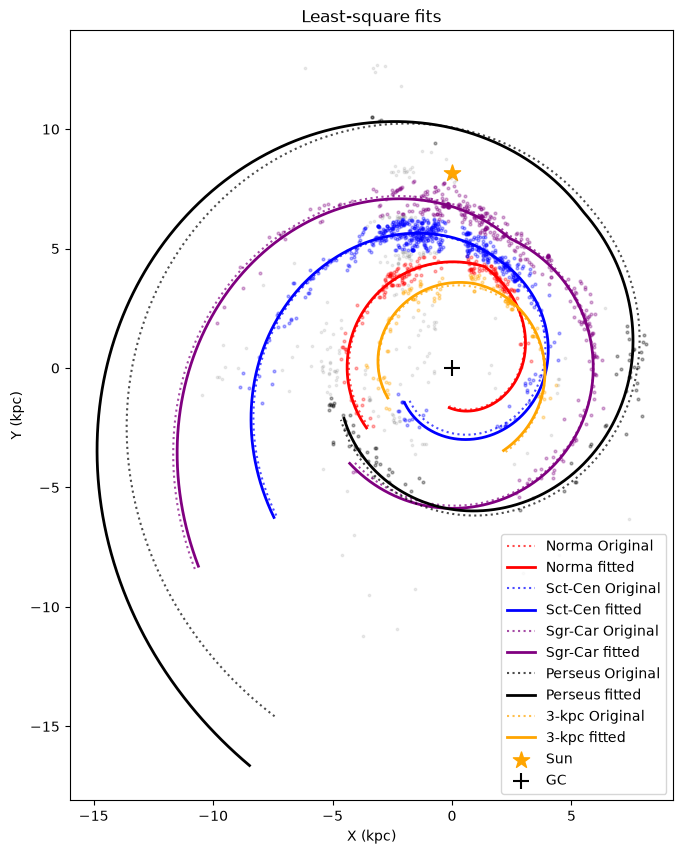

In [16]:
# Plot fitted arms

fig, ax = plt.subplots(figsize=(10, 10))

for name in arm_names:

    original = extended_arms[name]
    fitted = fitted_arms[name]

    # Initial Reid geometry
    ax.plot(
        original["X"],
        original["Y"],
        color=colours[name],
        ls=":",
        lw=1.5,
        alpha=0.7,
        label = f"{name} Original"
    )

    # Newly fitted geometry
    ax.plot(
        fitted["X"],
        fitted["Y"],
        color=colours[name],
        ls="-",
        lw=2,
        label=f"{name} fitted"
    )

    # Clouds assigned to this arm
    subset = df_2[df_2["assigned_arm"] == name]

    ax.scatter(
        subset["X_kpc"],
        subset["Y_kpc"],
        s=4,
        color=colours[name],
        alpha=0.3,
        rasterized=True
    )

unassigned = df_2[df_2["assigned_arm"] == "Unassigned"]

ax.scatter(
    unassigned["X_kpc"],
    unassigned["Y_kpc"],
    s=3,
    color="grey",
    alpha=0.15,
    rasterized=True,
    zorder=2
)

ax.scatter(0, R0, marker="*", s=150, color="orange", label="Sun")
ax.scatter(0, 0, marker="+", s=120, color="black", label="GC")

ax.set_xlabel("X (kpc)")
ax.set_ylabel("Y (kpc)")
ax.set_aspect("equal")
ax.set_title('Least-square fits')
ax.legend()
plt.show()

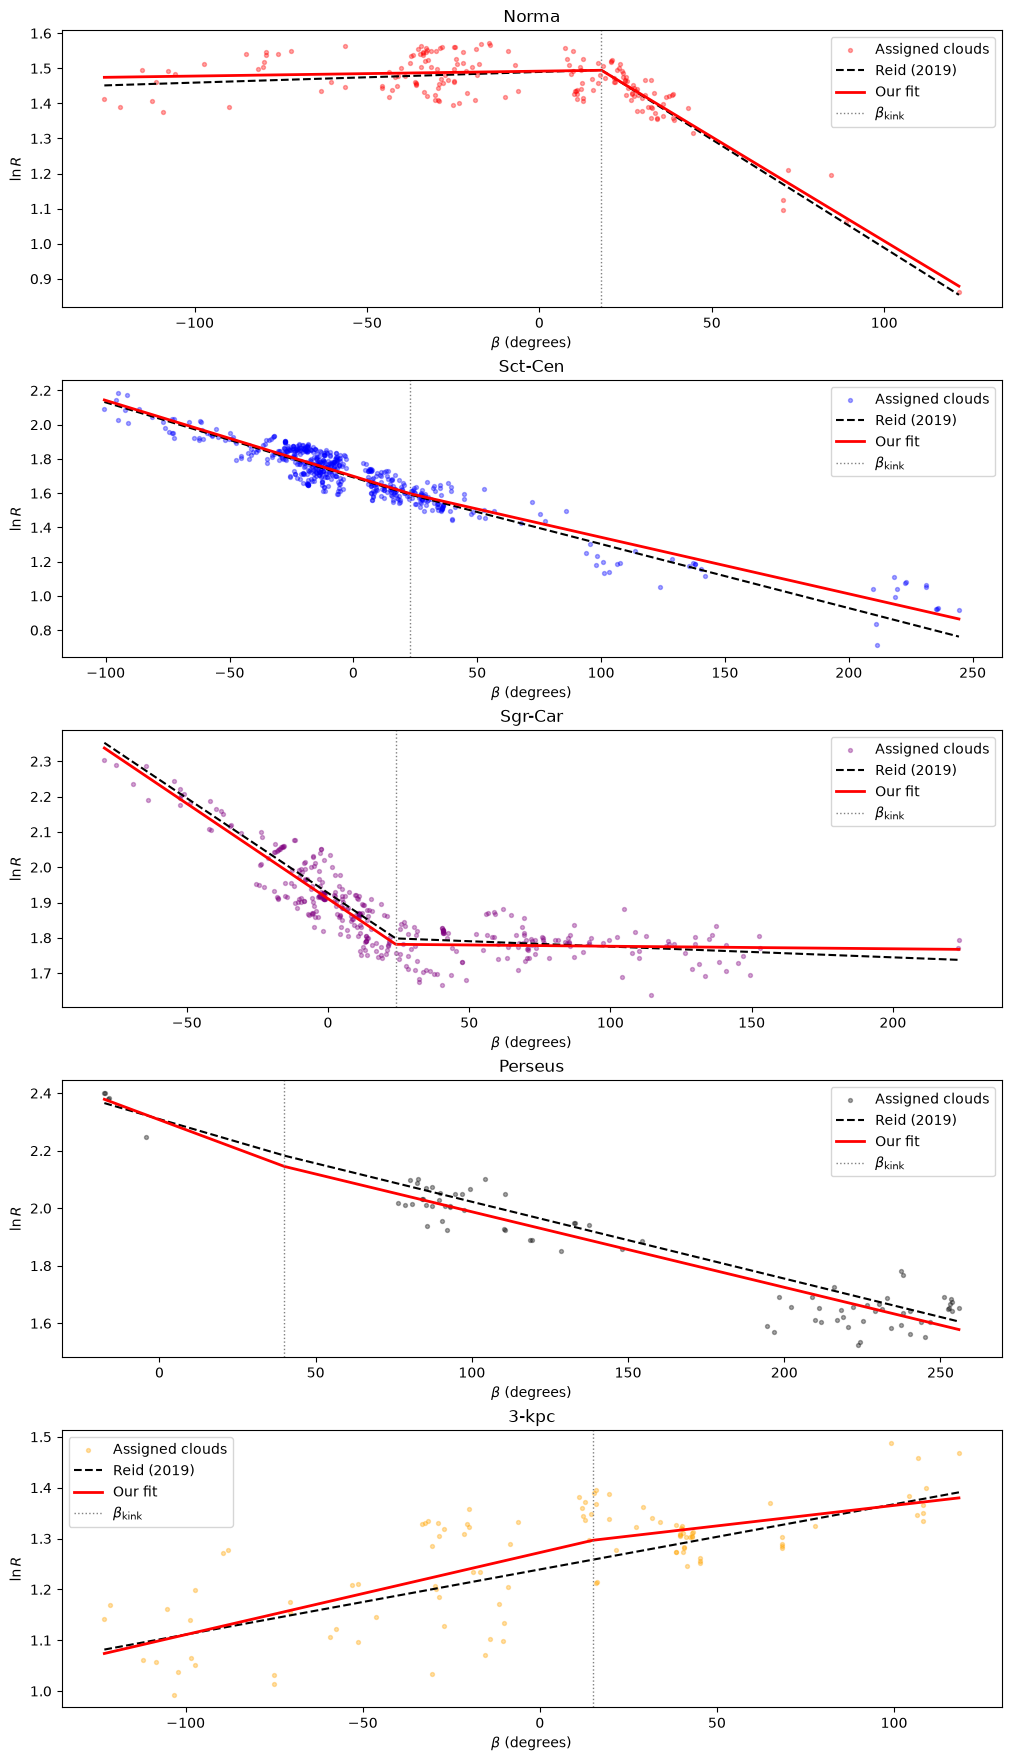

In [17]:
# Check fits of arms vs points (including both sides of the kink)

fig, axes = plt.subplots(
    len(arm_names), 1,
    figsize=(10, 3.5 * len(arm_names)),
    constrained_layout=True
)

# Store fitted results for easy lookup
fit_lookup = {result["name"]: result for result in fit_results}

for ax, name in zip(axes, arm_names):

    # Clouds assigned to this arm
    subset = df_2.loc[
        (df_2["assigned_arm"] == name)
        & np.isfinite(df_2["beta_unwrapped_deg"])
        & np.isfinite(df_2["R_kpc"])
        & (df_2["R_kpc"] > 0)
    ]

    if subset.empty:
        ax.set_title(f"{name} (no assigned clouds)")
        continue

    beta_cloud = subset["beta_unwrapped_deg"].to_numpy()
    lnR_cloud = np.log(subset["R_kpc"].to_numpy())

    # Original Reid parameters
    _, _, bkink, Rkink, p_low, p_high = parameters[name]

    # Grid covering the observed azimuth interval
    beta_grid = np.linspace(
        beta_cloud.min(),
        beta_cloud.max(),
        500
    )

    # Reid model: use the appropriate pitch angle on each side
    pitch_reid = np.where(
        beta_grid <= bkink,
        p_low,
        p_high
    )

    lnR_reid = (
        np.log(Rkink)
        - np.radians(beta_grid - bkink)
        * np.tan(np.radians(pitch_reid))
    )

    # Plot assigned clouds
    ax.scatter(
        beta_cloud,
        lnR_cloud,
        s=8,
        color=colours[name],
        alpha=0.35,
        label="Assigned clouds"
    )

    # Plot Reid model
    ax.plot(
        beta_grid,
        lnR_reid,
        "k--",
        lw=1.5,
        label="Reid (2019)"
    )

    # Plot our fitted model, if available
    result = fit_lookup.get(name)

    if result is not None:

        pitch_fit = np.where(
            beta_grid <= bkink,
            result["pitch_low_fit"],
            result["pitch_high_fit"]
        )

        lnR_fit = (
            np.log(result["Rkink_fit"])
            - np.radians(beta_grid - bkink)
            * np.tan(np.radians(pitch_fit))
        )

        ax.plot(
            beta_grid,
            lnR_fit,
            color="red",
            lw=2,
            label="Our fit"
        )

    # Mark Reid's kink if it lies within the plotted interval
    if beta_grid.min() <= bkink <= beta_grid.max():
        ax.axvline(
            bkink,
            color="gray",
            ls=":",
            lw=1,
            label=r"$\beta_{\rm kink}$"
        )

    ax.set_title(name)
    ax.set_xlabel(r"$\beta$ (degrees)")
    ax.set_ylabel(r"$\ln R$")

    ax.legend()

plt.show()

In [18]:
# Turns out outliers impact the fit negatively even for the full sample. 
# Try a different fit, Huber loss. Similar to least squares but less sensitive to outliers

def fit_robust_arm(
    df, name, parameters,
    min_points=20,
    min_side_points=2,
    f_scale=0.03
):

    _, _, bkink, Rkink, p_low, p_high = parameters[name]

    # Select clouds assigned to this arm
    subset = df.loc[
        (df["assigned_arm"] == name)
        & np.isfinite(df["beta_unwrapped_deg"])
        & np.isfinite(df["R_kpc"])
        & (df["R_kpc"] > 0)
    ]

    if len(subset) < min_points:
        print('Not enough points!', name)
        return None

    beta = subset["beta_unwrapped_deg"].to_numpy(dtype=float)
    R = subset["R_kpc"].to_numpy(dtype=float)

    # Angular distance from kink, in radians
    x = np.radians(beta - bkink)
    y = np.log(R)

    # Separate the two sides of the kink
    x_low = np.minimum(x, 0.0)
    x_high = np.maximum(x, 0.0)

    n_low = np.sum(x <= 0)
    n_high = np.sum(x > 0)

    # Require adequate coverage on both sides
    if n_low < min_side_points or n_high < min_side_points:
        print('Not enough side points!', name, n_low, n_high)
        return None

    # Design matrix for continuous piecewise-linear model
    A = np.column_stack([
        np.ones_like(x),
        x_low,
        x_high
    ])

    # Initial solution from ordinary least squares
    theta0 = np.linalg.lstsq(A, y, rcond=None)[0]

    # Residuals in ln(R)
    def residuals(theta):
        return y - A @ theta

    # Robust fitting with Huber loss
    result = least_squares(
        residuals,
        x0=theta0,
        loss="huber",
        f_scale=f_scale
    )

    if not result.success:
        return None

    a_fit, m_low_fit, m_high_fit = result.x

    return {
        "name": name,
        "N": len(subset),
        "N_low": int(n_low),
        "N_high": int(n_high),

        "Rkink_fit": np.exp(a_fit),

        "pitch_low_fit": np.degrees(
            np.arctan(-m_low_fit)
        ),

        "pitch_high_fit": np.degrees(
            np.arctan(-m_high_fit)
        ),

        "Rkink_Reid": Rkink,
        "pitch_low_Reid": p_low,
        "pitch_high_Reid": p_high
    }

In [19]:
# Robust Huber fitting for all arms

robust_results = []

for name in arm_names:

    robust_result = fit_robust_arm(
        df_2,
        name,
        parameters,
        min_points=20,
        min_side_points=2,
        f_scale=0.03
    )

    if robust_result is not None:
        robust_results.append(robust_result)

robust_table = pd.DataFrame(robust_results)

if not robust_table.empty:
    print(robust_table.round(3).to_string(index=False))
else:
    print("No arms met the fitting requirements.")

   name   N  N_low  N_high  Rkink_fit  pitch_low_fit  pitch_high_fit  Rkink_Reid  pitch_low_Reid  pitch_high_Reid
  Norma 177    118      59      4.458         -0.297          19.072        4.46            -1.0             19.5
Sct-Cen 561    448     113      4.924         14.570          10.410        4.91            14.1             12.1
Sgr-Car 359    222     137      5.946         17.253           0.093        6.04            17.1              1.0
Perseus  81      5      76      8.536         13.620           8.574        8.87            10.3              8.7
  3-kpc 106     56      50      3.683         -5.727          -1.655        3.52            -4.2             -4.2


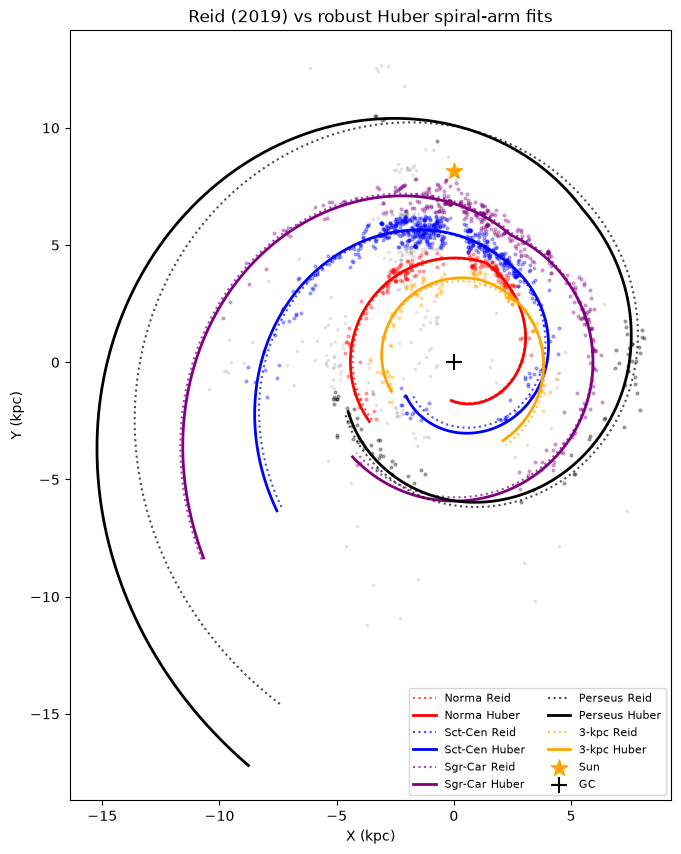

In [20]:
# Plot original Reid arms and robust Huber fits

fig, ax = plt.subplots(figsize=(10, 10))

# Lookup for robust fitting results
robust_lookup = {r["name"]: r for r in robust_results}

for name in arm_names:

    original = extended_arms[name]

    # Initial Reid geometry
    ax.plot(
        original["X"],
        original["Y"],
        color=colours[name],
        ls=":",
        lw=1.5,
        alpha=0.7,
        label=f"{name} Reid"
    )

    # Robust Huber fitted geometry
    result = robust_lookup.get(name)

    if result is not None:

        # Use the same unwrapped azimuth range as the Reid curve
        beta_grid = original["beta"]

        # Reid kink azimuth
        bkink = parameters[name][2]

        # Two-pitch-angle Huber model
        pitch = np.where(
            beta_grid <= bkink,
            result["pitch_low_fit"],
            result["pitch_high_fit"]
        )

        R_fit = result["Rkink_fit"] * np.exp(
            -np.radians(beta_grid - bkink)
            * np.tan(np.radians(pitch))
        )

        X_fit = R_fit * np.sin(np.radians(beta_grid))
        Y_fit = R_fit * np.cos(np.radians(beta_grid))

        ax.plot(
            X_fit,
            Y_fit,
            color=colours[name],
            ls="-",
            lw=2,
            label=f"{name} Huber"
        )

    # Clouds assigned to this arm
    subset = df_2[df_2["assigned_arm"] == name]

    ax.scatter(
        subset["X_kpc"],
        subset["Y_kpc"],
        s=4,
        color=colours[name],
        alpha=0.3,
        rasterized=True
    )

# Unassigned clouds
unassigned = df_2[df_2["assigned_arm"] == "Unassigned"]

ax.scatter(
    unassigned["X_kpc"],
    unassigned["Y_kpc"],
    s=3,
    color="grey",
    alpha=0.15,
    rasterized=True,
    zorder=2
)

# Sun and Galactic centre
ax.scatter(
    0, R0,
    marker="*",
    s=150,
    color="orange",
    label="Sun"
)

ax.scatter(
    0, 0,
    marker="+",
    s=120,
    color="black",
    label="GC"
)

ax.set_xlabel("X (kpc)")
ax.set_ylabel("Y (kpc)")
ax.set_aspect("equal")
ax.set_title("Reid (2019) vs robust Huber spiral-arm fits")
ax.legend(fontsize=8, ncol=2)

plt.show()

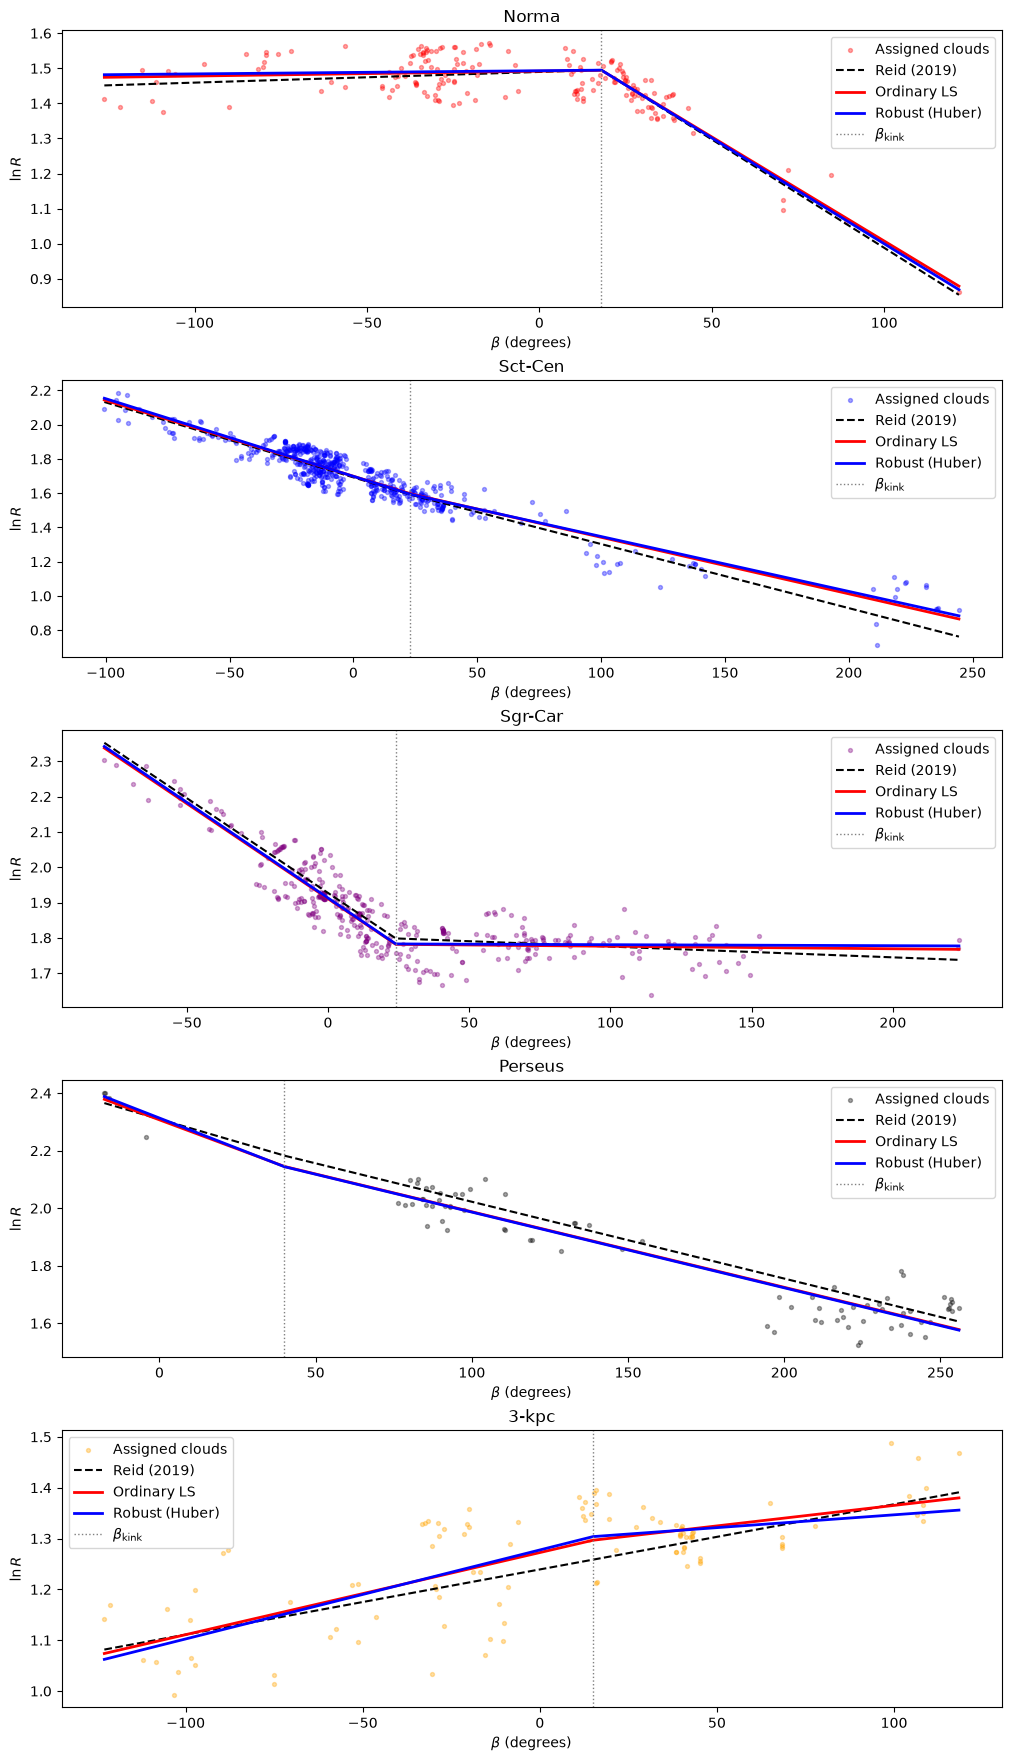

In [21]:
# Compare Reid, ordinary least squares, and robust fits

fig, axes = plt.subplots(
    len(arm_names), 1,
    figsize=(10, 3.5 * len(arm_names)),
    constrained_layout=True,
    squeeze=False
)

axes = axes.ravel()

# Create lookup dictionaries
fit_lookup = {r["name"]: r for r in fit_results}
robust_lookup = {r["name"]: r for r in robust_results}

for ax, name in zip(axes, arm_names):

    # Select valid clouds assigned to this arm
    subset = df_2.loc[
        (df_2["assigned_arm"] == name)
        & np.isfinite(df_2["beta_unwrapped_deg"])
        & np.isfinite(df_2["R_kpc"])
        & (df_2["R_kpc"] > 0)
    ]

    if subset.empty:
        ax.set_title(f"{name} (no assigned clouds)")
        continue

    beta_cloud = subset["beta_unwrapped_deg"].to_numpy()
    lnR_cloud = np.log(subset["R_kpc"].to_numpy())

    # Original Reid parameters
    _, _, bkink, Rkink, p_low, p_high = parameters[name]

    # Grid spanning the observed cloud azimuths
    # Include the kink explicitly if it lies within the interval
    beta_grid = np.linspace(
        beta_cloud.min(),
        beta_cloud.max(),
        500
    )

    if beta_grid.min() < bkink < beta_grid.max():
        beta_grid = np.sort(np.r_[beta_grid, bkink])

    # Helper: continuous two-pitch logarithmic spiral
    def model_lnR(beta, Rkink, pitch_low, pitch_high):
        pitch = np.where(
            beta <= bkink,
            pitch_low,
            pitch_high
        )

        return (
            np.log(Rkink)
            - np.radians(beta - bkink)
            * np.tan(np.radians(pitch))
        )

    # Reid model
    lnR_reid = model_lnR(
        beta_grid, Rkink, p_low, p_high
    )

    # Plot molecular clouds
    ax.scatter(
        beta_cloud,
        lnR_cloud,
        s=8,
        color=colours[name],
        alpha=0.35,
        label="Assigned clouds"
    )

    # Plot Reid model
    ax.plot(
        beta_grid,
        lnR_reid,
        "k--",
        lw=1.5,
        label="Reid (2019)"
    )

    # Ordinary least-squares fit
    result = fit_lookup.get(name)

    if result is not None:

        lnR_fit = model_lnR(
            beta_grid,
            result["Rkink_fit"],
            result["pitch_low_fit"],
            result["pitch_high_fit"]
        )

        ax.plot(
            beta_grid,
            lnR_fit,
            color="red",
            lw=2,
            label="Ordinary LS"
        )

    # Robust Huber fit
    result_robust = robust_lookup.get(name)

    if result_robust is not None:

        lnR_rob = model_lnR(
            beta_grid,
            result_robust["Rkink_fit"],
            result_robust["pitch_low_fit"],
            result_robust["pitch_high_fit"]
        )

        ax.plot(
            beta_grid,
            lnR_rob,
            color="blue",
            lw=2,
            label="Robust (Huber)"
        )

    # Mark the kink if covered by the observations
    if beta_grid.min() <= bkink <= beta_grid.max():
        ax.axvline(
            bkink,
            color="gray",
            ls=":",
            lw=1,
            label=r"$\beta_{\rm kink}$"
        )

    ax.set_title(name)
    ax.set_xlabel(r"$\beta$ (degrees)")
    ax.set_ylabel(r"$\ln R$")

    ax.legend()

plt.show()


## Caution with these plots. For Perseus, Sct-Cen and Sgr-Car you see Reid missing them by a lot. That is a mistake, they are not at 
## azimuth -100 but actually at b > 100. if you take the same points, keep their lnR the same and move them to teh far right then
## they fit well!

In [22]:
## Investigate cloud-arm distance

# Look up fitted parameters
fit_lookup = {r["name"]: r for r in fit_results}
robust_lookup = {r["name"]: r for r in robust_results}

def spiral_xy(beta, bkink, Rkink, pitch_low, pitch_high):
    """
    Calculate Cartesian coordinates for a continuous
    two-pitch-angle logarithmic spiral.

    beta and pitch angles are in degrees.
    Radii and Cartesian coordinates are in kpc.
    """

    pitch = np.where(
        beta <= bkink,
        pitch_low,
        pitch_high
    )

    R = Rkink * np.exp(
        -np.radians(beta - bkink)
        * np.tan(np.radians(pitch))
    )

    X = R * np.sin(np.radians(beta))
    Y = R * np.cos(np.radians(beta))

    return np.column_stack([X, Y])


def cloud_arm_distances(cloud_xy, beta_grid,
                        bkink, Rkink, pitch_low, pitch_high):

    arm_xy = spiral_xy(
        beta_grid, bkink, Rkink, pitch_low, pitch_high
    )

    tree = cKDTree(arm_xy)

    distances, _ = tree.query(cloud_xy)

    return distances

In [23]:
# Initialize distance columns
for model in ["Reid", "OLS", "Huber"]:
    df_2[f"residual_{model}_kpc"] = np.nan

for name in arm_names:

    subset = df_2.loc[
        (df_2["assigned_arm"] == name)
        & np.isfinite(df_2["X_kpc"])
        & np.isfinite(df_2["Y_kpc"])
        & np.isfinite(df_2["beta_unwrapped_deg"])
    ]

    if subset.empty:
        continue

    cloud_xy = subset[["X_kpc", "Y_kpc"]].to_numpy()  ## Array for all clouds assigned to an arm, not single cloud

    beta_cloud = subset["beta_unwrapped_deg"].to_numpy()

    # Same comparison interval for all models
    beta_grid = np.linspace(
        beta_cloud.min() - 5,
        beta_cloud.max() + 5,
        10000
    )

    _, _, bkink, Rkink, p_low, p_high = parameters[name]

    models = {
        "Reid": (Rkink, p_low, p_high)
    }

    if name in fit_lookup:
        r = fit_lookup[name]
        models["OLS"] = (
            r["Rkink_fit"],
            r["pitch_low_fit"],
            r["pitch_high_fit"]
        )

    if name in robust_lookup:
        r = robust_lookup[name]
        models["Huber"] = (
            r["Rkink_fit"],
            r["pitch_low_fit"],
            r["pitch_high_fit"]
        )

    for model_name, (radius, pitch1, pitch2) in models.items():

        distances = cloud_arm_distances(  ## Array of all distances ofclouds associated to arm, with arm
            cloud_xy,
            beta_grid,
            bkink,
            radius,
            pitch1,
            pitch2
        )

        df_2.loc[
            subset.index,
            f"residual_{model_name}_kpc"
        ] = distances

In [24]:
comparison = []

for name in arm_names:

    subset = df_2[df_2["assigned_arm"] == name]

    width = arm_widths[name]

    for model in ["Reid", "OLS", "Huber"]:

        d = subset[f"residual_{model}_kpc"].dropna().to_numpy()

        if len(d) == 0:
            continue

        comparison.append({
            "Arm": name,
            "Model": model,
            "N": len(d),
            "Median_kpc": np.median(d),
            "RMS_kpc": np.sqrt(np.mean(d**2)),
            "Within_1w_%": 100 * np.mean(d <= width),
            "Within_2w_%": 100 * np.mean(d <= 2 * width)
        })

comparison_table = pd.DataFrame(comparison)

print(comparison_table.round(3).to_string(index=False))

    Arm Model   N  Median_kpc  RMS_kpc  Within_1w_%  Within_2w_%
  Norma  Reid 177       0.152    0.205       45.198       76.271
  Norma   OLS 177       0.153    0.201       45.763       79.661
  Norma Huber 177       0.151    0.201       45.763       79.661
Sct-Cen  Reid 561       0.257    0.337       46.702       78.610
Sct-Cen   OLS 561       0.237    0.332       47.950       80.927
Sct-Cen Huber 561       0.238    0.333       48.307       79.679
Sgr-Car  Reid 359       0.207    0.330       59.889       87.465
Sgr-Car   OLS 359       0.212    0.319       60.167       90.529
Sgr-Car Huber 359       0.215    0.319       59.053       90.808
Perseus  Reid  81       0.317    0.427       53.086       90.123
Perseus   OLS  81       0.279    0.384       65.432       92.593
Perseus Huber  81       0.274    0.385       64.198       92.593
  3-kpc  Reid 106       0.170    0.265       53.774       76.415
  3-kpc   OLS 106       0.185    0.248       48.113       83.962
  3-kpc Huber 106       0

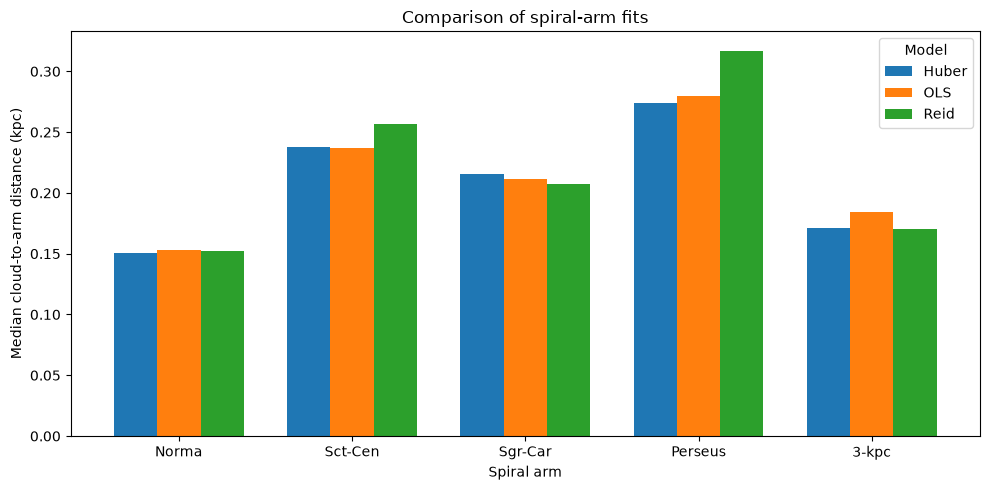

In [25]:
median_table = comparison_table.pivot(  # This turns the 15 x 1 column Median_kpc you see above into a 5 x 3 table, model vs arm
    index="Arm",
    columns="Model",
    values="Median_kpc"
)  

median_table = median_table.reindex(arm_names)

ax = median_table.plot(
    kind="bar",
    figsize=(10, 5),
    width=0.75
)

ax.set_ylabel("Median cloud-to-arm distance (kpc)")
ax.set_xlabel("Spiral arm")
ax.set_title("Comparison of spiral-arm fits")
ax.legend(title="Model")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

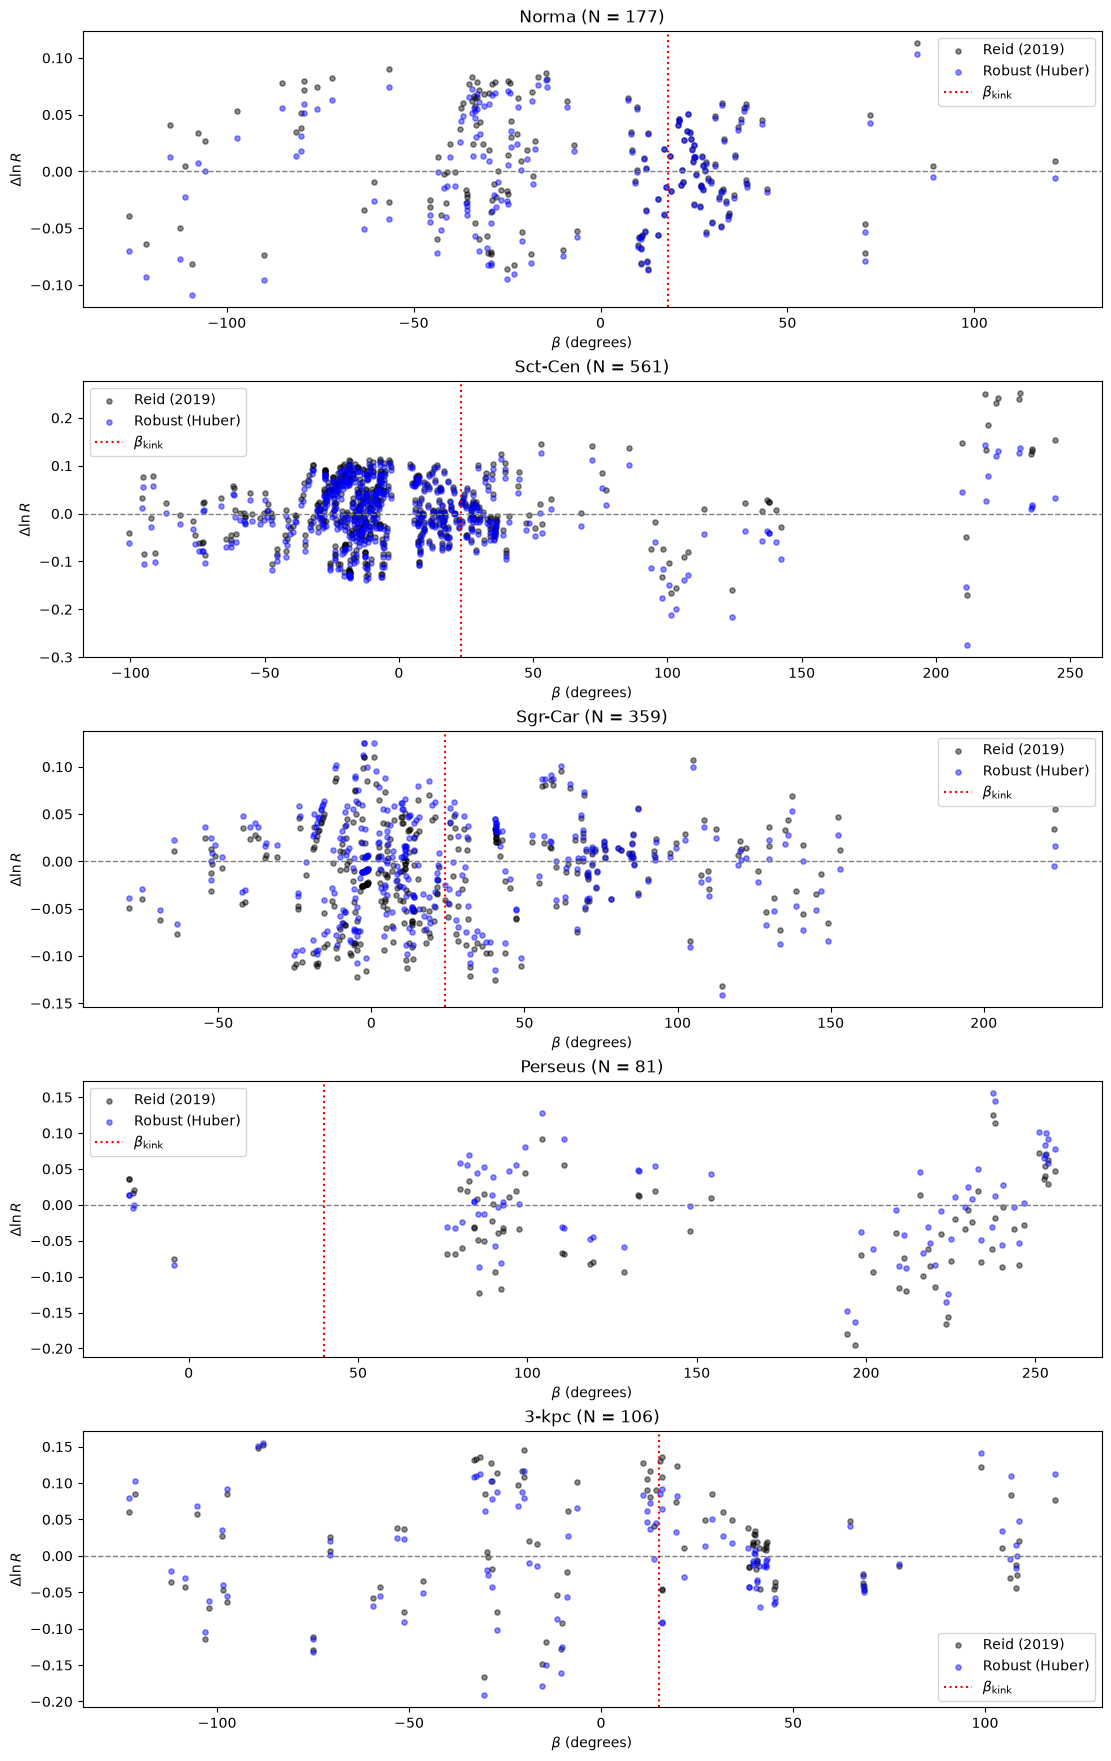

In [26]:
# Lookup for robust fitting results
# Plot the residuals, we want our points in the plots to be close to 0.
robust_lookup = {r["name"]: r for r in robust_results}

def spiral_lnR(beta, bkink, Rkink, pitch_low, pitch_high):
    """
    Logarithmic radius of a two-pitch-angle spiral.
    All angles are in degrees.
    """

    pitch = np.where(
        beta <= bkink,
        pitch_low,
        pitch_high
    )

    return (
        np.log(Rkink)
        - np.radians(beta - bkink)
        * np.tan(np.radians(pitch))
    )


fig, axes = plt.subplots(
    len(arm_names), 1,
    figsize=(11, 3.5 * len(arm_names)),
    constrained_layout=True,
    squeeze=False
)

axes = axes.ravel()

for ax, name in zip(axes, arm_names):

    # Select valid clouds
    subset = df_2.loc[
        (df_2["assigned_arm"] == name)
        & np.isfinite(df_2["beta_unwrapped_deg"])
        & np.isfinite(df_2["R_kpc"])
        & (df_2["R_kpc"] > 0)
    ]

    if subset.empty:
        ax.set_title(f"{name} (no assigned clouds)")
        continue

    beta = subset["beta_unwrapped_deg"].to_numpy()
    lnR_cloud = np.log(subset["R_kpc"].to_numpy())

    # Original Reid parameters
    _, _, bkink, Rkink, p_low, p_high = parameters[name]

    # Reid predictions and residuals
    lnR_reid = spiral_lnR(
        beta, bkink, Rkink, p_low, p_high
    )

    residual_reid = lnR_cloud - lnR_reid

    ax.scatter(
        beta,
        residual_reid,
        s=14,
        color="black",
        alpha=0.45,
        label="Reid (2019)"
    )

    # Robust Huber predictions and residuals
    result = robust_lookup.get(name)

    if result is not None:

        lnR_huber = spiral_lnR(
            beta,
            bkink,
            result["Rkink_fit"],
            result["pitch_low_fit"],
            result["pitch_high_fit"]
        )

        residual_huber = lnR_cloud - lnR_huber

        ax.scatter(
            beta,
            residual_huber,
            s=14,
            color="blue",
            alpha=0.45,
            label="Robust (Huber)"
        )

    # Zero residual reference
    ax.axhline(
        0,
        color="gray",
        linestyle="--",
        linewidth=1
    )

    # Reid kink azimuth
    if beta.min() <= bkink <= beta.max():
        ax.axvline(
            bkink,
            color="red",
            linestyle=":",
            linewidth=1.5,
            label=r"$\beta_{\rm kink}$"
        )

    ax.set_title(f"{name} (N = {len(subset)})")
    ax.set_xlabel(r"$\beta$ (degrees)")
    ax.set_ylabel(r"$\Delta \ln R$")

    ax.legend()

plt.show()

In [27]:
df_2.columns

Index(['Universal_ID', 'v_cen', 'x_cen', 'y_cen', 'final_distance', 'Mass',
       'sigv_kms', 'has_match', 'AGAL_distance', 'X_kpc', 'Y_kpc', 'R_kpc',
       'beta_deg', 'ln_R', 'dist_Norma_kpc', 'dist_Sct-Cen_kpc',
       'dist_Sgr-Car_kpc', 'dist_Perseus_kpc', 'dist_3-kpc_kpc', 'nearest_arm',
       'arm_distance_kpc', 'assigned_arm', 'beta_unwrapped_deg',
       'beta_winding', 'z_Norma', 'z_Sct-Cen', 'z_Sgr-Car', 'z_Perseus',
       'z_3-kpc', 'arm_z', 'second_best_z', 'arm_separation_z',
       'residual_Reid_kpc', 'residual_OLS_kpc', 'residual_Huber_kpc'],
      dtype='str')

# Experiment two: 4-parameter fit

In [28]:
# Define the fitting function
# No need to rerun this

def fit_reid_arm_4param(df, name, parameters, min_points=2):

    _, _, bkink, Rkink, p_low, p_high = parameters[name]

    subset = df.loc[
        (df["assigned_arm"] == name)
        & np.isfinite(df["beta_unwrapped_deg"])
        & np.isfinite(df["R_kpc"])
        & (df["R_kpc"] > 0)
    ].copy()

    if len(subset) < min_points:
        return None

    beta = subset["beta_unwrapped_deg"].to_numpy(dtype=float)
    y = np.log(subset["R_kpc"].to_numpy(dtype=float))

    # Parameters:
    # ln(Rkink), beta_kink (degrees), pitch_low, pitch_high (degrees)

    def residuals(theta):

        lnRk, bk, plow, phigh = theta

        x = np.radians(beta - bk)

        pitch = np.where(
            beta <= bk,
            plow,
            phigh
        )

        y_model = lnRk - x * np.tan(np.radians(pitch))

        return y - y_model

    # Initial guess from Reid et al. (2019)
    theta0 = [
        np.log(Rkink),
        bkink,
        p_low,
        p_high
    ]

    # Initial exploratory bounds
    lower = [
        np.log(0.5),
        bkink - 60,
        -45,
        -45
    ]

    upper = [
        np.log(30.0),
        bkink + 60,
        45,
        45
    ]

    result = least_squares(
        residuals,
        x0=theta0,
        bounds=(lower, upper),
        loss="linear"
    )

    if not result.success:
        return None

    lnRk_fit, bk_fit, plow_fit, phigh_fit = result.x

    n_low = np.sum(beta <= bk_fit)
    n_high = np.sum(beta > bk_fit)

    # Restore Reid's low-side pitch if no clouds constrain it
    if n_low == 0:
        plow_fit = phigh_fit

    return {
        "name": name,
        "N": len(subset),
        "Rkink_fit": np.exp(lnRk_fit),
        "bkink_fit": bk_fit,
        "pitch_low_fit": plow_fit,
        "pitch_high_fit": phigh_fit,
        "Rkink_Reid": Rkink,
        "bkink_Reid": bkink,
        "pitch_low_Reid": p_low,
        "pitch_high_Reid": p_high,
        "RMSE_lnR": np.sqrt(np.mean(result.fun**2)),
        "N_low": int(n_low),
        "N_high": int(n_high),
    }

In [29]:
# Fit the clouds

fit_results_4param = []

for name in arm_names:

    result = fit_reid_arm_4param(
        df_2, name, parameters
    )

    if result is not None:
        fit_results_4param.append(result)

fit_table_4param = pd.DataFrame(fit_results_4param)

print(fit_table_4param.round(3).to_string(index=False))

   name   N  Rkink_fit  bkink_fit  pitch_low_fit  pitch_high_fit  Rkink_Reid  bkink_Reid  pitch_low_Reid  pitch_high_Reid  RMSE_lnR  N_low  N_high
  Norma 177      4.435     19.776         -0.234          19.243        4.46          18            -1.0             19.5     0.047    120      57
Sct-Cen 561      3.816     83.000         14.059           8.555        4.91          23            14.1             12.1     0.062    528      33
Sgr-Car 359      5.941     23.919         17.169           0.245        6.04          24            17.1              1.0     0.050    221     138
Perseus  81      9.714     -8.938         40.094           8.554        8.87          40            10.3              8.7     0.064      4      77
  3-kpc 106      3.648     12.791         -5.334          -2.669        3.52          15            -4.2             -4.2     0.072     52      54


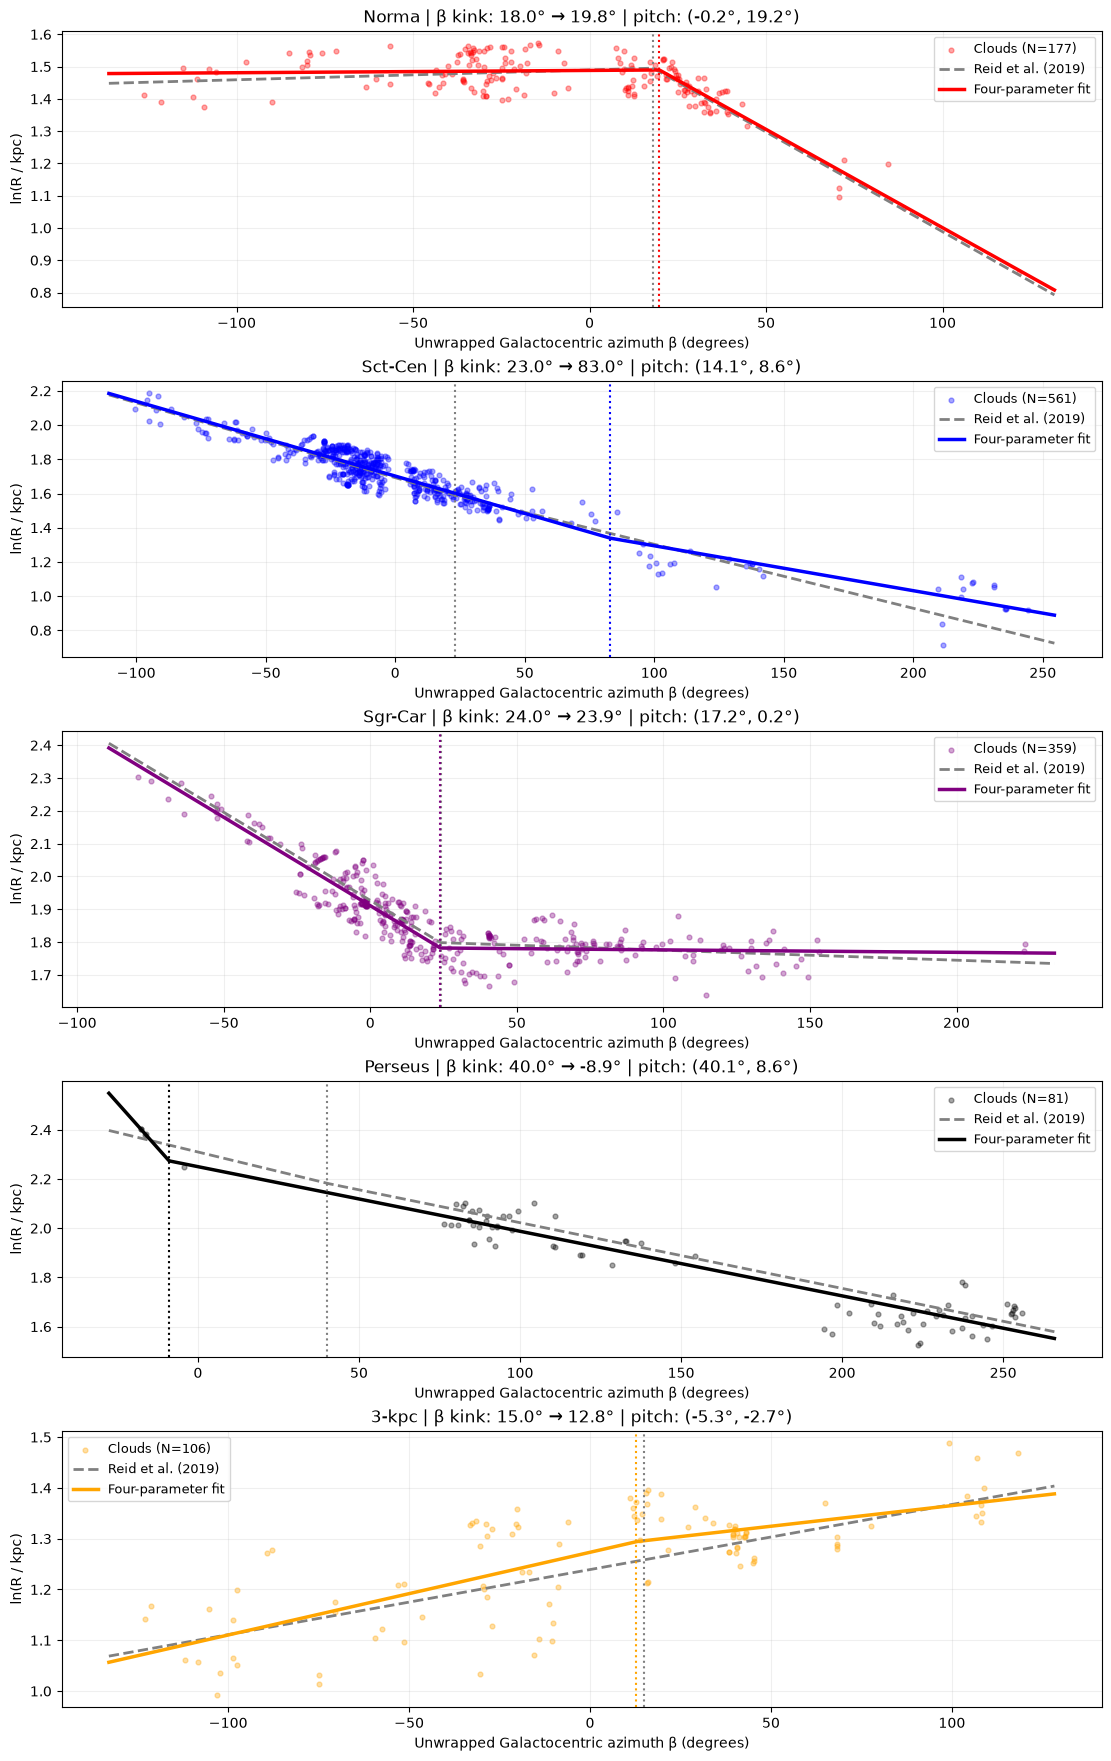

In [30]:
# Plot this bitch
fig, axes = plt.subplots(
    len(arm_names), 1,
    figsize=(11, 3.5 * len(arm_names)),
    constrained_layout=True
)

def model_lnR(beta, bk, Rk, pl, ph):
        pitch = np.where(beta <= bk, pl, ph)
        return (
            np.log(Rk)
            - np.radians(beta - bk)
            * np.tan(np.radians(pitch))
        )

fit_lookup = {
    result["name"]: result
    for result in fit_results_4param
}

for ax, name in zip(axes, arm_names):

    if name not in fit_lookup:
        ax.set_title(f"{name}: no successful fit")
        continue

    fit = fit_lookup[name]

    _, _, bk_reid, Rk_reid, pl_reid, ph_reid = parameters[name]

    bk_fit = fit["bkink_fit"]
    Rk_fit = fit["Rkink_fit"]
    pl_fit = fit["pitch_low_fit"]
    ph_fit = fit["pitch_high_fit"]

    subset = df_2.loc[
        (df_2["assigned_arm"] == name)
        & np.isfinite(df_2["beta_unwrapped_deg"])
        & np.isfinite(df_2["R_kpc"])
        & (df_2["R_kpc"] > 0)
    ]

    beta_cloud = subset["beta_unwrapped_deg"].to_numpy()
    lnR_cloud = np.log(subset["R_kpc"].to_numpy())

    # Include clouds and both kink positions in the plot
    beta_min = min(beta_cloud.min(), bk_reid, bk_fit) - 10
    beta_max = max(beta_cloud.max(), bk_reid, bk_fit) + 10

    beta_grid = np.linspace(beta_min, beta_max, 1000)

    lnR_reid = model_lnR(
        beta_grid, bk_reid, Rk_reid, pl_reid, ph_reid
    )

    lnR_fit = model_lnR(
        beta_grid, bk_fit, Rk_fit, pl_fit, ph_fit
    )

    # Molecular clouds
    ax.scatter(
        beta_cloud, lnR_cloud,
        s=12, alpha=0.35,
        color=colours[name],
        label=f"Clouds (N={len(subset)})"
    )

    # Original Reid model
    ax.plot(
        beta_grid, lnR_reid,
        "--", color="gray", lw=2,
        label="Reid et al. (2019)"
    )

    # Four-parameter fit
    ax.plot(
        beta_grid, lnR_fit,
        color=colours[name], lw=2.5,
        label="Four-parameter fit"
    )

    # Kink locations
    ax.axvline(
        bk_reid, color="gray",
        ls=":", lw=1.5
    )

    ax.axvline(
        bk_fit, color=colours[name],
        ls=":", lw=1.5
    )

    ax.set_title(
        f"{name} | "
        f"β kink: {bk_reid:.1f}° → {bk_fit:.1f}° | "
        f"pitch: ({pl_fit:.1f}°, {ph_fit:.1f}°)"
    )

    ax.set_xlabel("Unwrapped Galactocentric azimuth β (degrees)")
    ax.set_ylabel("ln(R / kpc)")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=9)

plt.show()

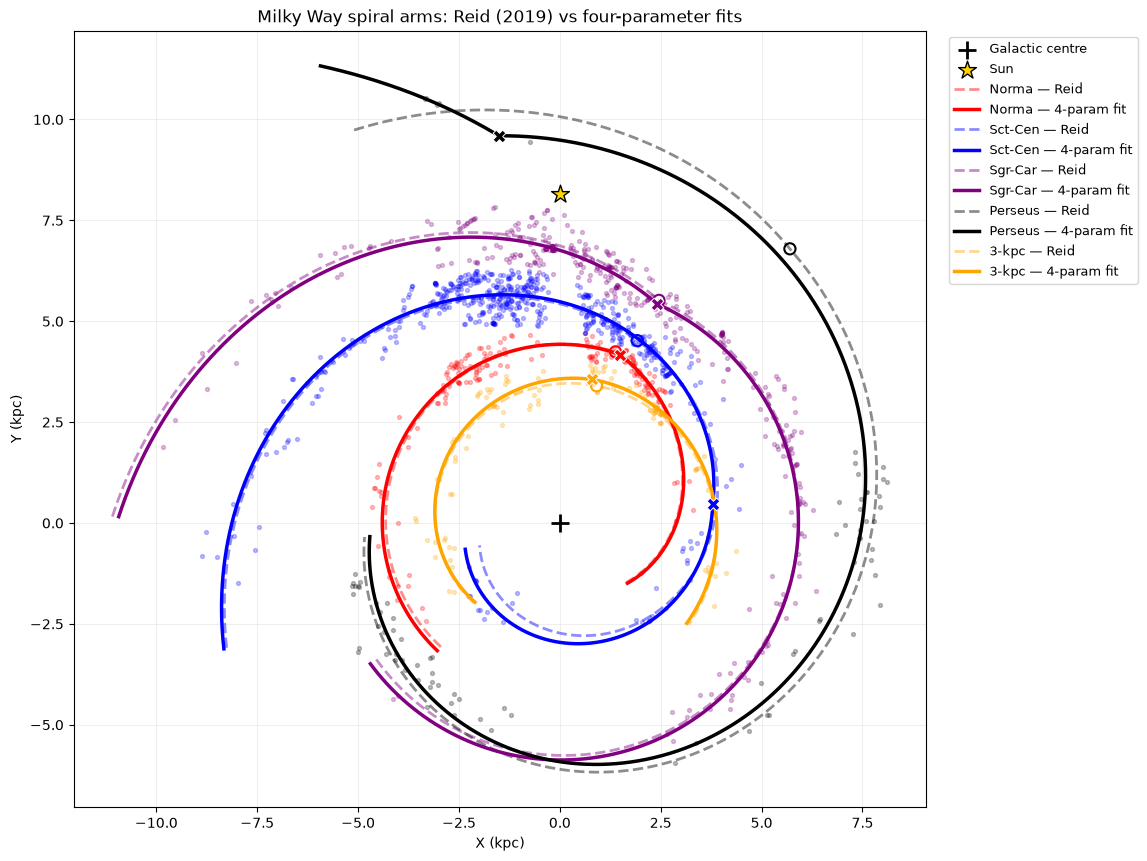

In [31]:
fit_lookup = {
    result["name"]: result
    for result in fit_results_4param
}

def spiral_xy(beta, bk, Rk, pl, ph):
    """Two-pitch logarithmic spiral, with beta in degrees."""

    beta = np.asarray(beta, dtype=float)

    pitch = np.where(beta <= bk, pl, ph)

    lnR = (
        np.log(Rk)
        - np.radians(beta - bk) * np.tan(np.radians(pitch))
    )

    R = np.exp(lnR)

    X = R * np.sin(np.radians(beta))
    Y = R * np.cos(np.radians(beta))

    return X, Y


fig, ax = plt.subplots(figsize=(11, 11))

# Galactic centre and Sun
ax.scatter(0, 0, marker="+", s=180, color="black",
           linewidths=2, label="Galactic centre", zorder=10)

ax.scatter(0, R0, marker="*", s=180, color="gold",
           edgecolor="black", label="Sun", zorder=10)


for name in arm_names:

    if name not in fit_lookup:
        continue

    fit = fit_lookup[name]

    bmin, bmax, bk_reid, Rk_reid, pl_reid, ph_reid = parameters[name]

    bk_fit = fit["bkink_fit"]
    Rk_fit = fit["Rkink_fit"]
    pl_fit = fit["pitch_low_fit"]
    ph_fit = fit["pitch_high_fit"]

    # Clouds assigned to this arm
    subset = df_2.loc[
        (df_2["assigned_arm"] == name)
        & np.isfinite(df_2["X_kpc"])
        & np.isfinite(df_2["Y_kpc"])
        & np.isfinite(df_2["beta_unwrapped_deg"])
    ]

    beta_cloud = subset["beta_unwrapped_deg"].to_numpy()

    if len(beta_cloud) == 0:
        continue

    # Plot over the observed azimuth range, including both kinks
    beta_min = min(beta_cloud.min(), bk_reid, bk_fit) - 10
    beta_max = max(beta_cloud.max(), bk_reid, bk_fit) + 10

    beta_grid = np.linspace(beta_min, beta_max, 1500)

    # Original Reid spiral
    X_reid, Y_reid = spiral_xy(
        beta_grid, bk_reid, Rk_reid, pl_reid, ph_reid
    )

    # Four-parameter fitted spiral
    X_fit, Y_fit = spiral_xy(
        beta_grid, bk_fit, Rk_fit, pl_fit, ph_fit
    )

    # Clouds
    ax.scatter(
        subset["X_kpc"],
        subset["Y_kpc"],
        s=8,
        alpha=0.25,
        color=colours[name],
        zorder=2
    )

    # Reid model: dashed
    ax.plot(
        X_reid, Y_reid,
        "--", color=colours[name],
        alpha=0.45, lw=2,
        label=f"{name} — Reid",
        zorder=3
    )

    # Fitted model: solid
    ax.plot(
        X_fit, Y_fit,
        "-", color=colours[name],
        lw=2.5,
        label=f"{name} — 4-param fit",
        zorder=4
    )

    # Original Reid kink
    Xkr, Ykr = spiral_xy(
        bk_reid, bk_reid, Rk_reid, pl_reid, ph_reid
    )

    ax.scatter(
        Xkr, Ykr,
        marker="o", s=65,
        facecolors="none",
        edgecolors=colours[name],
        linewidths=1.5,
        zorder=6
    )

    # Fitted kink
    Xkf, Ykf = spiral_xy(
        bk_fit, bk_fit, Rk_fit, pl_fit, ph_fit
    )

    ax.scatter(
        Xkf, Ykf,
        marker="X", s=85,
        color=colours[name],
        edgecolors="white",
        linewidths=0.7,
        zorder=7
    )


ax.set_xlabel("X (kpc)")
ax.set_ylabel("Y (kpc)")
ax.set_title("Milky Way spiral arms: Reid (2019) vs four-parameter fits")

ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=0.2)

ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    fontsize=9
)

plt.show()

In [32]:
# Huber loss with 4 parameters

def fit_robust_reid_arm_4param(
    df, name, parameters,
    min_points=20,
    f_scale=0.03
):

    _, _, bkink, Rkink, p_low, p_high = parameters[name]

    subset = df.loc[
        (df["assigned_arm"] == name)
        & np.isfinite(df["beta_unwrapped_deg"])
        & np.isfinite(df["R_kpc"])
        & (df["R_kpc"] > 0)
    ].copy()

    if len(subset) < min_points:
        return None

    beta = subset["beta_unwrapped_deg"].to_numpy(dtype=float)
    y = np.log(subset["R_kpc"].to_numpy(dtype=float))

    # Parameters:
    # ln(Rkink), beta_kink (degrees), pitch_low, pitch_high (degrees)

    def residuals(theta):

        lnRk, bk, plow, phigh = theta

        x = np.radians(beta - bk)

        pitch = np.where(
            beta <= bk,
            plow,
            phigh
        )

        y_model = lnRk - x * np.tan(np.radians(pitch))

        return y - y_model


    # Reid parameters as initial guess
    theta0 = [
        np.log(Rkink),
        bkink,
        p_low,
        p_high
    ]

    # Same bounds as our previous four-parameter OLS fit
    lower = [
        np.log(0.5),
        bkink - 60,
        -45,
        -45
    ]

    upper = [
        np.log(30.0),
        bkink + 60,
        45,
        45
    ]

    result = least_squares(
        residuals,
        x0=theta0,
        bounds=(lower, upper),
        loss="huber",
        f_scale=f_scale
    )

    if not result.success:
        return None

    lnRk_fit, bk_fit, plow_fit, phigh_fit = result.x
    n_low = np.sum(beta <= bk_fit)
    n_high = np.sum(beta > bk_fit)

    # Restore Reid's low-side pitch if no clouds constrain it
    if n_low == 0:
        plow_fit = phigh_fit
        
    return {
        "name": name,
        "N": len(subset),
        "N_low": int(n_low),
        "N_high": int(n_high),
        "Rkink_fit": np.exp(lnRk_fit),
        "bkink_fit": bk_fit,
        "pitch_low_fit": plow_fit,
        "pitch_high_fit": phigh_fit,
        "Rkink_Reid": Rkink,
        "bkink_Reid": bkink,
        "pitch_low_Reid": p_low,
        "pitch_high_Reid": p_high,
        "RMSE_lnR": np.sqrt(np.mean(result.fun**2))
    }

In [33]:
robust_results_4param = []

for name in arm_names:

    result = fit_robust_reid_arm_4param(
        df_2, name, parameters
    )

    if result is not None:
        robust_results_4param.append(result)

robust_table_4param = pd.DataFrame(robust_results_4param)

print(robust_table_4param.round(3).to_string(index=False))

   name   N  N_low  N_high  Rkink_fit  bkink_fit  pitch_low_fit  pitch_high_fit  Rkink_Reid  bkink_Reid  pitch_low_Reid  pitch_high_Reid  RMSE_lnR
  Norma 177    120      57      4.419     20.490          0.081          19.545        4.46          18            -1.0             19.5     0.047
Sct-Cen 561    528      33      3.781     83.000         14.392           8.171        4.91          23            14.1             12.1     0.062
Sgr-Car 359    219     140      5.995     21.489         17.695           0.397        6.04          24            17.1              1.0     0.050
Perseus  81      4      77      9.685     -8.734         40.095           8.541        8.87          40            10.3              8.7     0.064
  3-kpc 106     50      56      3.676     11.364         -5.919          -1.647        3.52          15            -4.2             -4.2     0.073


In [34]:
comparison = fit_table_4param[
    [
        "name",
        "bkink_fit",
        "pitch_low_fit",
        "pitch_high_fit"
    ]
].merge(
    robust_table_4param[
        [
            "name",
            "bkink_fit",
            "pitch_low_fit",
            "pitch_high_fit"
        ]
    ],
    on="name",
    suffixes=("_OLS", "_Huber")
)

print(comparison.round(2).to_string(index=False))

   name  bkink_fit_OLS  pitch_low_fit_OLS  pitch_high_fit_OLS  bkink_fit_Huber  pitch_low_fit_Huber  pitch_high_fit_Huber
  Norma          19.78              -0.23               19.24            20.49                 0.08                 19.55
Sct-Cen          83.00              14.06                8.56            83.00                14.39                  8.17
Sgr-Car          23.92              17.17                0.25            21.49                17.69                  0.40
Perseus          -8.94              40.09                8.55            -8.73                40.09                  8.54
  3-kpc          12.79              -5.33               -2.67            11.36                -5.92                 -1.65


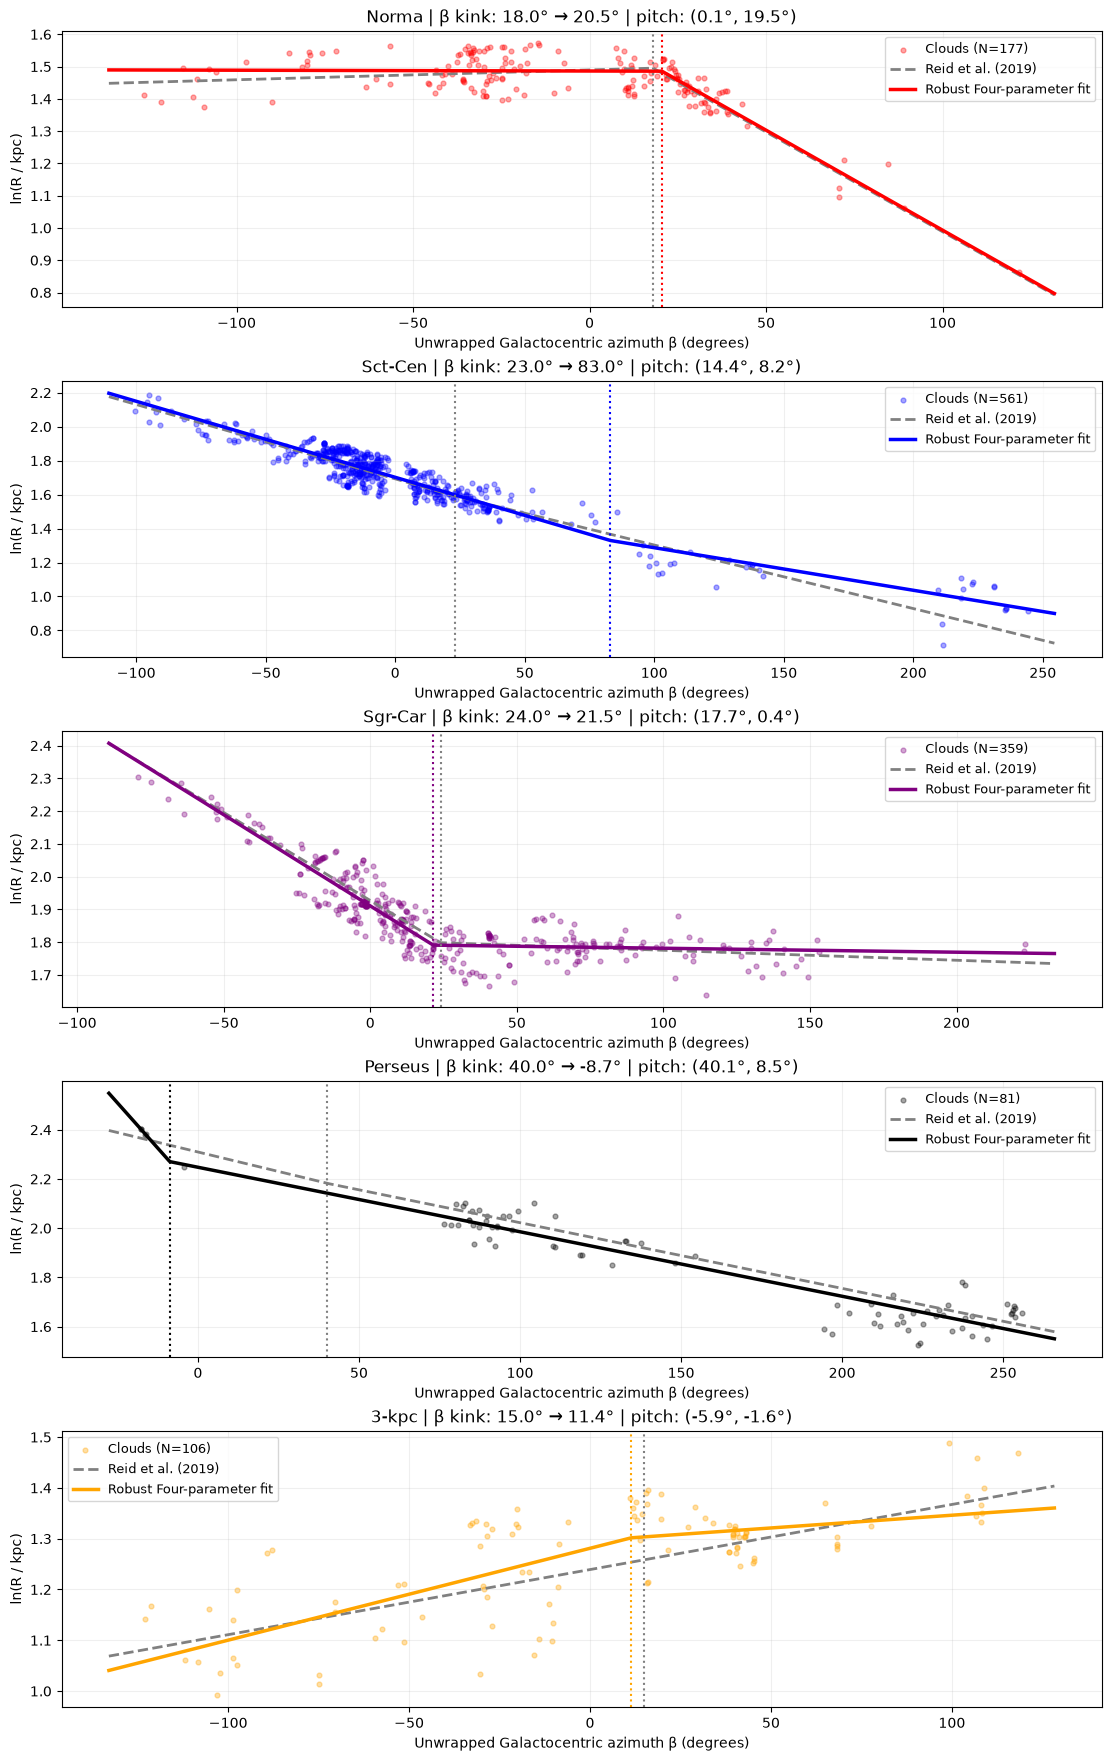

In [35]:
# Plot this bitch
fig, axes = plt.subplots(
    len(arm_names), 1,
    figsize=(11, 3.5 * len(arm_names)),
    constrained_layout=True
)

fit_lookup_Huber = {
    result["name"]: result
    for result in robust_results_4param
}

for ax, name in zip(axes, arm_names):

    if name not in fit_lookup_Huber:
        ax.set_title(f"{name}: no successful fit")
        continue

    fit = fit_lookup_Huber[name]

    _, _, bk_reid, Rk_reid, pl_reid, ph_reid = parameters[name]

    bk_fit = fit["bkink_fit"]
    Rk_fit = fit["Rkink_fit"]
    pl_fit = fit["pitch_low_fit"]
    ph_fit = fit["pitch_high_fit"]

    subset = df_2.loc[
        (df_2["assigned_arm"] == name)
        & np.isfinite(df_2["beta_unwrapped_deg"])
        & np.isfinite(df_2["R_kpc"])
        & (df_2["R_kpc"] > 0)
    ]

    beta_cloud = subset["beta_unwrapped_deg"].to_numpy()
    lnR_cloud = np.log(subset["R_kpc"].to_numpy())

    # Include clouds and both kink positions in the plot
    beta_min = min(beta_cloud.min(), bk_reid, bk_fit) - 10
    beta_max = max(beta_cloud.max(), bk_reid, bk_fit) + 10

    beta_grid = np.linspace(beta_min, beta_max, 1000)

    lnR_reid = model_lnR(
        beta_grid, bk_reid, Rk_reid, pl_reid, ph_reid
    )

    lnR_fit = model_lnR(
        beta_grid, bk_fit, Rk_fit, pl_fit, ph_fit
    )

    # Molecular clouds
    ax.scatter(
        beta_cloud, lnR_cloud,
        s=12, alpha=0.35,
        color=colours[name],
        label=f"Clouds (N={len(subset)})"
    )

    # Original Reid model
    ax.plot(
        beta_grid, lnR_reid,
        "--", color="gray", lw=2,
        label="Reid et al. (2019)"
    )

    # Four-parameter fit
    ax.plot(
        beta_grid, lnR_fit,
        color=colours[name], lw=2.5,
        label="Robust Four-parameter fit"
    )

    # Kink locations
    ax.axvline(
        bk_reid, color="gray",
        ls=":", lw=1.5
    )

    ax.axvline(
        bk_fit, color=colours[name],
        ls=":", lw=1.5
    )

    ax.set_title(
        f"{name} | "
        f"β kink: {bk_reid:.1f}° → {bk_fit:.1f}° | "
        f"pitch: ({pl_fit:.1f}°, {ph_fit:.1f}°)"
    )

    ax.set_xlabel("Unwrapped Galactocentric azimuth β (degrees)")
    ax.set_ylabel("ln(R / kpc)")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=9)

plt.show()

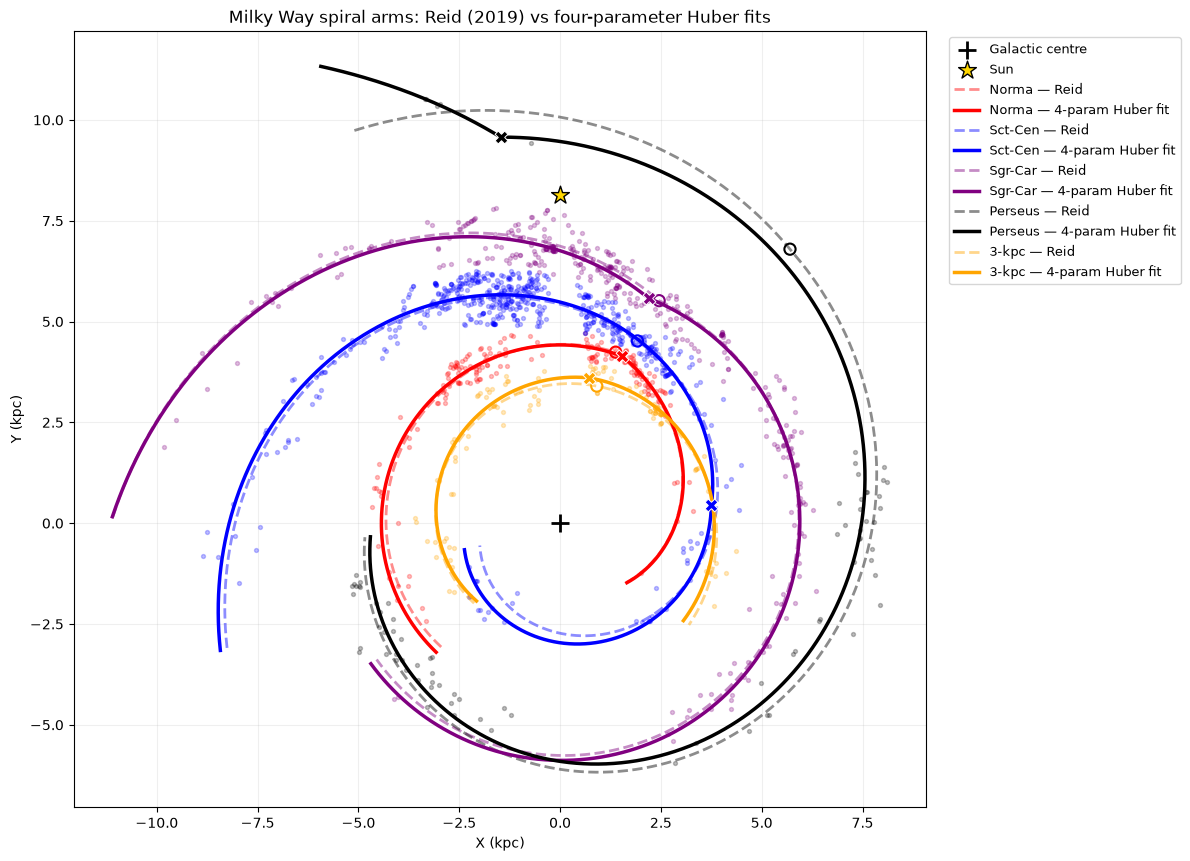

In [36]:
fit_lookup_Huber = {
    result["name"]: result
    for result in robust_results_4param
}

fig, ax = plt.subplots(figsize=(11, 11))

# Galactic centre and Sun
ax.scatter(0, 0, marker="+", s=180, color="black",
           linewidths=2, label="Galactic centre", zorder=10)

ax.scatter(0, R0, marker="*", s=180, color="gold",
           edgecolor="black", label="Sun", zorder=10)


for name in arm_names:

    if name not in fit_lookup_Huber:
        continue

    fit = fit_lookup_Huber[name]

    bmin, bmax, bk_reid, Rk_reid, pl_reid, ph_reid = parameters[name]

    bk_fit = fit["bkink_fit"]
    Rk_fit = fit["Rkink_fit"]
    pl_fit = fit["pitch_low_fit"]
    ph_fit = fit["pitch_high_fit"]

    # Clouds assigned to this arm
    subset = df_2.loc[
        (df_2["assigned_arm"] == name)
        & np.isfinite(df_2["X_kpc"])
        & np.isfinite(df_2["Y_kpc"])
        & np.isfinite(df_2["beta_unwrapped_deg"])
    ]

    beta_cloud = subset["beta_unwrapped_deg"].to_numpy()

    if len(beta_cloud) == 0:
        continue

    # Plot over the observed azimuth range, including both kinks
    beta_min = min(beta_cloud.min(), bk_reid, bk_fit) - 10
    beta_max = max(beta_cloud.max(), bk_reid, bk_fit) + 10

    beta_grid = np.linspace(beta_min, beta_max, 1500)

    # Original Reid spiral
    X_reid, Y_reid = spiral_xy(
        beta_grid, bk_reid, Rk_reid, pl_reid, ph_reid
    )

    # Four-parameter fitted spiral
    X_fit, Y_fit = spiral_xy(
        beta_grid, bk_fit, Rk_fit, pl_fit, ph_fit
    )

    # Clouds
    ax.scatter(
        subset["X_kpc"],
        subset["Y_kpc"],
        s=8,
        alpha=0.25,
        color=colours[name],
        zorder=2
    )

    # Reid model: dashed
    ax.plot(
        X_reid, Y_reid,
        "--", color=colours[name],
        alpha=0.45, lw=2,
        label=f"{name} — Reid",
        zorder=3
    )

    # Fitted model: solid
    ax.plot(
        X_fit, Y_fit,
        "-", color=colours[name],
        lw=2.5,
        label=f"{name} — 4-param Huber fit",
        zorder=4
    )

    # Original Reid kink
    Xkr, Ykr = spiral_xy(
        bk_reid, bk_reid, Rk_reid, pl_reid, ph_reid
    )

    ax.scatter(
        Xkr, Ykr,
        marker="o", s=65,
        facecolors="none",
        edgecolors=colours[name],
        linewidths=1.5,
        zorder=6
    )

    # Fitted kink
    Xkf, Ykf = spiral_xy(
        bk_fit, bk_fit, Rk_fit, pl_fit, ph_fit
    )

    ax.scatter(
        Xkf, Ykf,
        marker="X", s=85,
        color=colours[name],
        edgecolors="white",
        linewidths=0.7,
        zorder=7
    )


ax.set_xlabel("X (kpc)")
ax.set_ylabel("Y (kpc)")
ax.set_title("Milky Way spiral arms: Reid (2019) vs four-parameter Huber fits")

ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=0.2)

ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    fontsize=9
)

plt.show()

In [134]:
## Saving the Huber arms to plot on top of the top-down plot

robust_lookup = {r["name"]: r for r in robust_results}

fitted_arms = []

for name in arm_names:

    result = robust_lookup.get(name)
    if result is None:
        continue

    # Same unwrapped azimuth grid as the extended Reid arm
    beta_grid = np.asarray(extended_arms[name]["beta"])

    # Fixed Reid kink azimuth
    bkink = parameters[name][2]

    pitch = np.where(
        beta_grid <= bkink,
        result["pitch_low_fit"],
        result["pitch_high_fit"]
    )

    R_fit = result["Rkink_fit"] * np.exp(
        -np.radians(beta_grid - bkink)
        * np.tan(np.radians(pitch))
    )

    X_fit = R_fit * np.sin(np.radians(beta_grid))
    Y_fit = R_fit * np.cos(np.radians(beta_grid))

    # Convert to heliocentric Galactic coordinates (l, b, d)
    l = np.degrees(np.arctan2(X_fit, R0 - Y_fit)) % 360
    b = np.zeros_like(l)
    d = np.hypot(X_fit, R0 - Y_fit)

    fitted_arms.append(pd.DataFrame({
        "arm": name,
        "x_cen": l,
        "y_cen": b,
        "final_distance": d,
        "has_match": False
    }))

fitted_arms_df = pd.concat(fitted_arms, ignore_index=True)

fitted_arms_df.to_csv(
    "Huber_3param_fitted_arms_galactic.csv",
    index=False
)

print(fitted_arms_df.head())

     arm       x_cen  y_cen  final_distance  has_match
0  Norma  341.338238    0.0       11.266693      False
1  Norma  341.289431    0.0       11.259698      False
2  Norma  341.240658    0.0       11.252685      False
3  Norma  341.191921    0.0       11.245654      False
4  Norma  341.143218    0.0       11.238606      False


In [135]:
## Saving the Reid arms to plot on top of the top-down plot

extended_arms = {
    name: reid_arm(
        name,
        extend_low  = 0,
        extend_high = 0
    )
    for name in arm_names
}

arms_df = pd.concat(
    [
        pd.DataFrame({
            "arm": name,
            "x_cen": np.degrees(
                np.arctan2(arm["X"], R0 - arm["Y"])
            ) % 360,
            "y_cen": np.zeros_like(arm["X"]),
            "final_distance": np.hypot(
                arm["X"], R0 - arm["Y"]
            ),
            "has_match": "False"
        })
        for name, arm in extended_arms.items()
    ],
    ignore_index=True
)

arms_df.to_csv("short_Reid_arms_galactic.csv", index=False)

# Fitting free models

### This part is a little exploratory, skip to calculating silhouettes if you want.
### Don't delete though, good for history and also plotting cell

In [20]:
def fit_spiral_model(  ## Only fits on the XY plane, doesn't take velocities into account
    df,
    n_arms,
    kink,
    max_distance,  # kpc
    max_iter=30,
    min_points=10,
    random_state= 153,
    n_curve_points=2000
):

    if n_arms < 1:
        raise ValueError("n_arms must be >= 1")

    if max_distance <= 0:
        raise ValueError("max_distance must be positive")

    cloud_df = df.copy()

    valid = (
        np.isfinite(df["X_kpc"])
        & np.isfinite(df["Y_kpc"])
    )

    valid_indices = df.index[valid]

    X = df.loc[valid, "X_kpc"].to_numpy(dtype=float)
    Y = df.loc[valid, "Y_kpc"].to_numpy(dtype=float)

    R = np.hypot(X, Y)

    positive = R > 0

    X = X[positive]
    Y = Y[positive]
    R = R[positive]

    valid_indices = valid_indices[positive]

    beta = np.arctan2(X, Y)
    lnR = np.log(R)

    xy = np.column_stack([X, Y])

    if len(R) < n_arms * min_points:
        raise ValueError("Not enough clouds for requested arms")

    # Common azimuth grid for evaluating model curves
    beta_grid = np.linspace(
        -np.pi, np.pi, n_curve_points
    )

    # ----------------------------------------
    # Spiral model
    # ----------------------------------------

    def model(theta, beta_values):

        if not kink:
            a, m = theta
            return a + m * beta_values

        a, bk, m_low, m_high = theta

        x = beta_values - bk

        return a + np.where(
            x <= 0,
            m_low * x,
            m_high * x
        )

    def curve_xy(theta):

        lnR_curve = model(theta, beta_grid)

        R_curve = np.exp(lnR_curve)

        X_curve = R_curve * np.sin(beta_grid)
        Y_curve = R_curve * np.cos(beta_grid)

        return np.column_stack([X_curve, Y_curve])

    # ----------------------------------------
    # Fit one arm
    # ----------------------------------------

    def fit_one_arm(beta_arm, lnR_arm, theta0=None):

        if not kink:

            if theta0 is None:
                A = np.column_stack([
                    np.ones_like(beta_arm),
                    beta_arm
                ])

                theta0 = np.linalg.lstsq(
                    A, lnR_arm, rcond=None
                )[0]

            return least_squares(
                lambda theta:
                    lnR_arm - model(theta, beta_arm),
                x0=theta0,
                loss="huber",
                f_scale=0.05
            ).x

        if theta0 is None:
            theta0 = [
                np.median(lnR_arm),
                np.median(beta_arm),
                -0.15,
                -0.15
            ]

        lower = [
            np.log(0.1),
            -np.pi,
            -1.0,
            -1.0
        ]

        upper = [
            np.log(50),
            np.pi,
            1.0,
            1.0
        ]

        theta0 = np.clip(
            theta0,
            np.array(lower) + 1e-6,
            np.array(upper) - 1e-6
        )

        return least_squares(
            lambda theta:
                lnR_arm - model(theta, beta_arm),
            x0=theta0,
            bounds=(lower, upper),
            loss="huber",
            f_scale=0.05
        ).x

    # ----------------------------------------
    # Initial arm geometries
    # ----------------------------------------

    km = KMeans(
        n_clusters=n_arms,
        random_state=random_state,
        n_init=10
    )

    labels = km.fit_predict(lnR.reshape(-1, 1))

    thetas = []

    for j in range(n_arms):

        mask = labels == j

        thetas.append(
            fit_one_arm(beta[mask], lnR[mask])
        )

    # ----------------------------------------
    # Iterative assignment and fitting
    # ----------------------------------------

    history = []

    for iteration in range(max_iter):

        distance_matrix = np.column_stack([
            cKDTree(curve_xy(theta)).query(xy)[0]
            for theta in thetas
        ])

        nearest_arm = np.argmin(distance_matrix, axis=1)

        nearest_distance = np.min(
            distance_matrix, axis=1
        )

        # -1 means unassigned
        new_labels = np.where(
            nearest_distance <= max_distance,
            nearest_arm,
            -1
        )

        changes = np.sum(new_labels != labels)

        new_thetas = []

        for j in range(n_arms):

            mask = new_labels == j

            if mask.sum() < min_points:

                # Keep previous geometry
                new_thetas.append(thetas[j])
                continue

            theta = fit_one_arm(
                beta[mask],
                lnR[mask],
                theta0=thetas[j]
            )

            new_thetas.append(theta)

        thetas = new_thetas
        labels = new_labels

        assigned = labels >= 0

        history.append({
            "iteration": iteration + 1,
            "changes": int(changes),
            "N_assigned": int(assigned.sum()),
            "N_unassigned": int((~assigned).sum())
        })

        if changes == 0:
            break

    # ----------------------------------------
    # Final reassignment using final curves
    # ----------------------------------------

    distance_matrix = np.column_stack([
        cKDTree(curve_xy(theta)).query(xy)[0]
        for theta in thetas
    ])

    nearest_arm = np.argmin(distance_matrix, axis=1)
    nearest_distance = np.min(distance_matrix, axis=1)

    labels = np.where(
        nearest_distance <= max_distance,
        nearest_arm,
        -1
    )

    # ----------------------------------------
    # Results
    # ----------------------------------------

    results = []

    for j, theta in enumerate(thetas):

        mask = labels == j

        if not kink:

            a, m = theta

            results.append({
                "arm": j + 1,
                "N": int(mask.sum()),
                "R_ref": np.exp(a),
                "pitch_deg": np.degrees(
                    np.arctan(-m)
                )
            })

        else:

            a, bk, m_low, m_high = theta

            results.append({
                "arm": j + 1,
                "N": int(mask.sum()),
                "R_kink": np.exp(a),
                "beta_kink_deg": np.degrees(bk),
                "pitch_low_deg": np.degrees(
                    np.arctan(-m_low)
                ),
                "pitch_high_deg": np.degrees(
                    np.arctan(-m_high)
                ),
                "N_low": int(np.sum(beta[mask] <= bk)),
                "N_high": int(np.sum(beta[mask] > bk))
            })

    cloud_df["model_arm"] = pd.Series(
        pd.NA, index=cloud_df.index, dtype="Int64"
    )

    cloud_df["distance_to_arm_kpc"] = np.nan

    cloud_df.loc[valid_indices, "model_arm"] = pd.array(
        np.where(labels >= 0, labels + 1, None),
        dtype="Int64"
    )

    cloud_df.loc[
        valid_indices, "distance_to_arm_kpc"
    ] = nearest_distance

    return pd.DataFrame(results), cloud_df, history

In [23]:
kink = True
max_distance = 0.5
n_arms = 4

results, assigned_clouds, history, fitted_Arms = fit_spiral_model(
    df_2,
    n_arms=n_arms,
    kink=kink,
    max_distance=max_distance
)


print(results.round(3).to_string(index=False))

print(
    "\nAssigned:",
    assigned_clouds["model_arm"].notna().sum()
)

print(
    "Unassigned:",
    assigned_clouds["model_arm"].isna().sum()
)

 arm  N  R_kink  beta_kink_deg  pitch_low_deg  pitch_high_deg  N_low  N_high
   1 27   5.603        -11.857          7.788          -2.381      6      21
   2 21   3.062       -140.689         22.156          -2.969      3      18
   3  0   1.102       -106.044         11.248          -5.570      0       0
   4 37   4.888        -12.046          0.027           3.328     18      19

Assigned: 85
Unassigned: 44


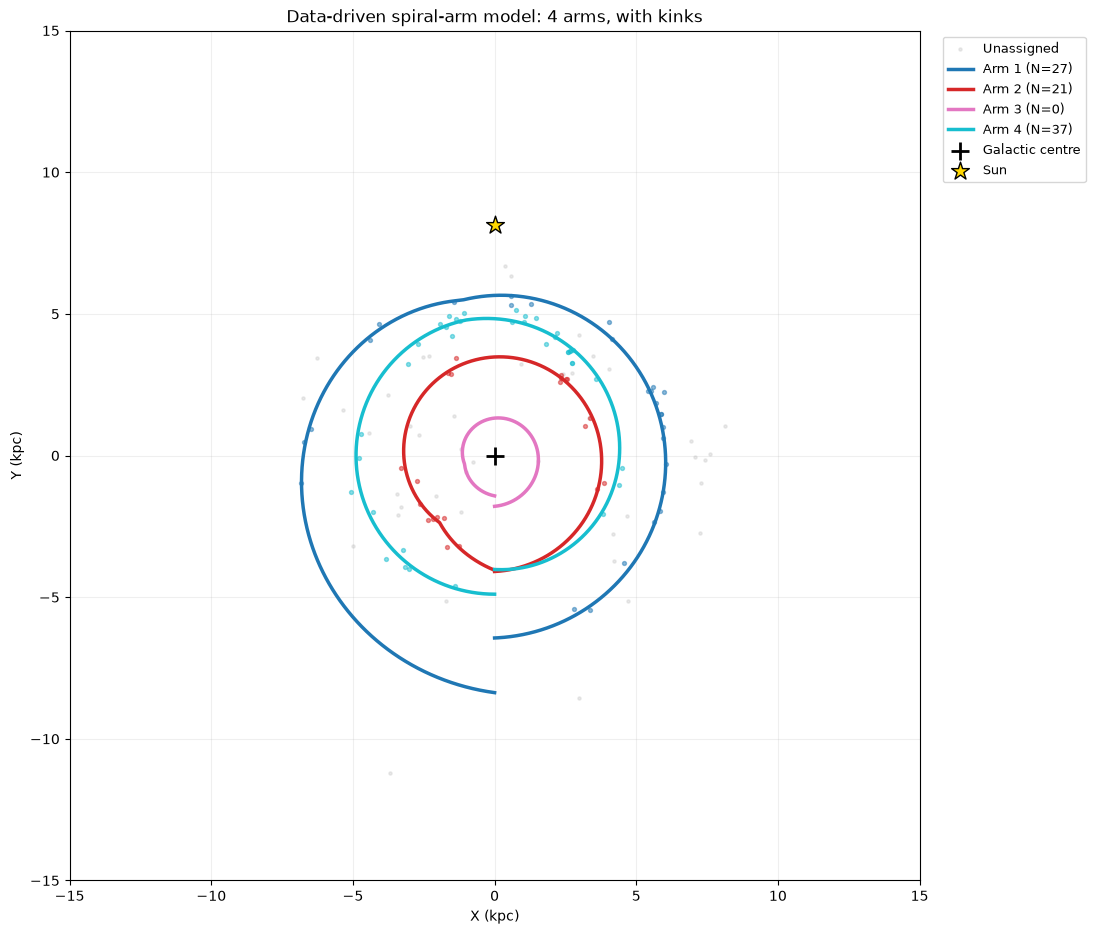

In [24]:
# Plot the model with the clouds
fig, ax = plt.subplots(figsize=(11, 11))

# Colours for the fitted arms
colours = plt.cm.tab10(np.linspace(0, 1, len(results)))

# Unassigned clouds
unassigned = assigned_clouds["model_arm"].isna()

ax.scatter(
    assigned_clouds.loc[unassigned, "X_kpc"],
    assigned_clouds.loc[unassigned, "Y_kpc"],
    s=5,
    color="lightgrey",
    alpha=0.5,
    label="Unassigned",
    zorder=1
)

# Common azimuth grid, matching the fitting function
beta_grid = np.linspace(-np.pi, np.pi, 2000)

for i, (_, arm) in enumerate(results.iterrows()):

    arm_id = int(arm["arm"])
    colour = colours[i]

    # Clouds assigned to this arm
    mask = assigned_clouds["model_arm"] == arm_id

    ax.scatter(
        assigned_clouds.loc[mask, "X_kpc"],
        assigned_clouds.loc[mask, "Y_kpc"],
        s=8,
        color=colour,
        alpha=0.5,
        zorder=2
    )

    # Reconstruct fitted spiral
    if not kink:

        a = np.log(arm["R_ref"])
        m = -np.tan(np.radians(arm["pitch_deg"]))

        lnR = a + m * beta_grid

    else:

        a = np.log(arm["R_kink"])
        bk = np.radians(arm["beta_kink_deg"])

        m_low = -np.tan(np.radians(arm["pitch_low_deg"]))
        m_high = -np.tan(np.radians(arm["pitch_high_deg"]))

        x = beta_grid - bk

        lnR = a + np.where(
            x <= 0,
            m_low * x,
            m_high * x
        )

    R = np.exp(lnR)

    X_arm = R * np.sin(beta_grid)
    Y_arm = R * np.cos(beta_grid)

    ax.plot(
        X_arm,
        Y_arm,
        color=colour,
        lw=2.5,
        label=f"Arm {arm_id} (N={int(arm['N'])})",
        zorder=4
    )

# Galactic centre
ax.scatter(
    0, 0,
    marker="+",
    s=180,
    color="black",
    linewidths=2,
    label="Galactic centre",
    zorder=10
)

# Sun
R0 = 8.15

ax.scatter(
    0, R0,
    marker="*",
    s=180,
    color="gold",
    edgecolor="black",
    label="Sun",
    zorder=10
)

ax.set_xlabel("X (kpc)")
ax.set_ylabel("Y (kpc)")

ax.set_title(
    f"Data-driven spiral-arm model: "
    f"{len(results)} arms, "
    f"{'with kinks' if kink else 'without kinks'}"
)

ax.set_aspect("equal", adjustable="box")
ax.set_xlim(-15, 15)
ax.set_ylim(-15, 15)
ax.grid(alpha=0.2)

ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    fontsize=9
)

plt.tight_layout()
plt.show()

In [20]:
def evaluate_spiral_model(
    results,
    assigned_clouds,
    kink=False,
    max_distance=0.5,
    min_arm_points=10
):
    valid = (
        np.isfinite(assigned_clouds["X_kpc"])
        & np.isfinite(assigned_clouds["Y_kpc"])
        & (
            np.hypot(
                assigned_clouds["X_kpc"],
                assigned_clouds["Y_kpc"]
            ) > 0
        )
    )

    df = assigned_clouds.loc[valid].copy()

    assigned = df["model_arm"].notna()

    distances = df.loc[
        assigned, "distance_to_arm_kpc"
    ].to_numpy(dtype=float)

    N_total = len(df)
    N_assigned = assigned.sum()
    N_unassigned = N_total - N_assigned

    coverage = N_assigned / N_total

    # Coverage-adjusted RMSE
    penalty_squared = (
        np.sum(distances**2)
        + N_unassigned * max_distance**2
    )

    adjusted_rmse = np.sqrt(
        penalty_squared / N_total
    )

    n_arms = len(results)
    n_parameters = n_arms * (4 if kink else 2)

    n_active_arms = (
        results["N"] >= min_arm_points
    ).sum()

    return {
        "N_arms": n_arms,
        "Kink": kink,
      #  "N_total": N_total,
        "N_assigned": N_assigned,
     #   "N_unassigned": N_unassigned,
        "Coverage": coverage,
        "Mean_d_kpc": (
            np.mean(distances) if len(distances) else np.nan
        ),
        "Median_d_kpc": (
            np.median(distances) if len(distances) else np.nan
        ),
        "P90_d_kpc": (
            np.percentile(distances, 90)
            if len(distances) else np.nan  ## Distance within 90% of clouds lie
        ),
        "Adjusted_RMSE_kpc": adjusted_rmse,
        "N_parameters": n_parameters,
        "N_active_arms": n_active_arms
    }

In [9]:
metrics = evaluate_spiral_model(
    results,
    assigned_clouds,
    kink=False,
    max_distance=0.5
)

print(pd.Series(metrics).round(3))

N_arms                   5
Kink                     0
N_assigned            1190
Coverage             0.799
Mean_d_kpc            0.22
Median_d_kpc         0.206
P90_d_kpc            0.414
Adjusted_RMSE_kpc    0.322
N_parameters            10
N_active_arms            5
dtype: object


In [10]:
model_metrics = []

for n_arms in range(1, 8):

    for kink in [False, True]:

        results, assigned_clouds, history = fit_spiral_model(
            df_2,
            n_arms=n_arms,
            kink=kink,
            max_distance=0.5
        )

        metrics = evaluate_spiral_model(
            results,
            assigned_clouds,
            kink=kink,
            max_distance=0.5
        )

        model_metrics.append(metrics)

comparison_df = pd.DataFrame(model_metrics)

print(
    comparison_df.sort_values(
        "Adjusted_RMSE_kpc"
    ).round(2).to_string(index=False)
)

 N_arms  Kink  N_assigned  Coverage  Mean_d_kpc  Median_d_kpc  P90_d_kpc  Adjusted_RMSE_kpc  N_parameters  N_active_arms
      7  True        1388      0.93        0.17          0.17       0.32               0.24            28              7
      7 False        1372      0.92        0.18          0.17       0.34               0.25            14              7
      6  True        1323      0.89        0.18          0.16       0.36               0.26            24              6
      6 False        1321      0.89        0.19          0.19       0.36               0.27            12              6
      5  True        1272      0.85        0.19          0.18       0.37               0.28            20              5
      4  True        1182      0.79        0.20          0.17       0.40               0.31            16              4
      5 False        1190      0.80        0.22          0.21       0.41               0.32            10              5
      4 False        1110      0

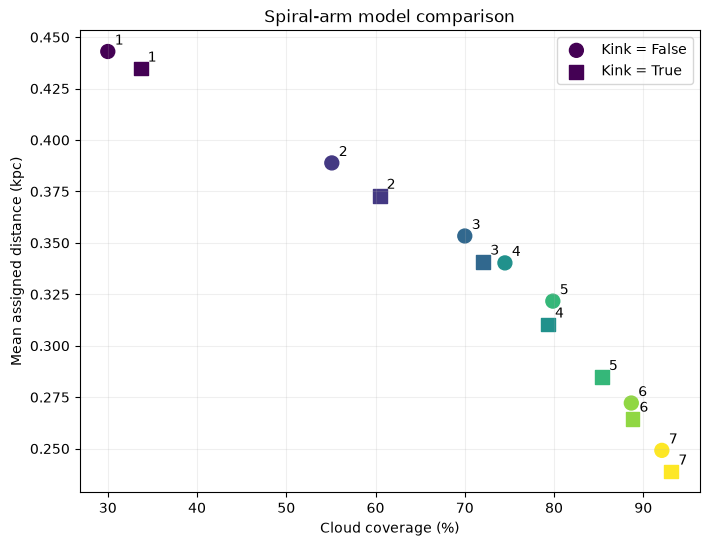

In [11]:
plt.figure(figsize=(8, 6))

for kink_value, marker in [(False, "o"), (True, "s")]:

    subset = comparison_df[
        comparison_df["Kink"] == kink_value
    ]

    plt.scatter(
        100 * subset["Coverage"],
        subset["Adjusted_RMSE_kpc"],
        c=subset["N_arms"],
        cmap="viridis",
        marker=marker,
        s=100,
        label=f"Kink = {kink_value}"
    )

    for _, row in subset.iterrows():
        plt.annotate(
            str(row["N_arms"]),
            (
                100 * row["Coverage"],
                row["Adjusted_RMSE_kpc"]
            ),
            xytext=(5, 5),
            textcoords="offset points"
        )

plt.xlabel("Cloud coverage (%)")
plt.ylabel("Mean assigned distance (kpc)")
plt.title("Spiral-arm model comparison")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

# Calculating silhouettes

In [22]:
## Also takes velocity into account
## Calculates velocities of the generated arms

def fit_spiral_model(
    df,
    n_arms,
    kink,
    max_distance,
    max_iter=30,
    min_points=10,
    random_state=153,
    n_curve_points=2000,
    velocity_col="v_cen",
    velocity_scale=0.03,
    R0=8.15,
    Theta0=236.0
):

    if n_arms < 1:
        raise ValueError("n_arms must be >= 1")

    if max_distance <= 0:
        raise ValueError("max_distance must be positive")

    if velocity_scale <= 0:
        raise ValueError("velocity_scale must be positive")

    cloud_df = df.copy()

    # ----------------------------------------
    # Valid cloud data
    # ----------------------------------------

    valid = (
        np.isfinite(df["X_kpc"])
        & np.isfinite(df["Y_kpc"])
        & np.isfinite(df[velocity_col])
    )

    valid_indices = df.index[valid]

    X = df.loc[valid, "X_kpc"].to_numpy(dtype=float)
    Y = df.loc[valid, "Y_kpc"].to_numpy(dtype=float)

    V = df.loc[valid, velocity_col].to_numpy(dtype=float) / 1000

    R = np.hypot(X, Y)

    positive = R > 0

    X = X[positive]
    Y = Y[positive]
    V = V[positive]
    R = R[positive]

    valid_indices = valid_indices[positive]

    beta = np.arctan2(X, Y)
    lnR = np.log(R)

    xy = np.column_stack([X, Y])

    xyz = np.column_stack([
        X,
        Y,
        V * velocity_scale
    ])

    if len(R) < n_arms * min_points:
        raise ValueError("Not enough clouds for requested arms")

    beta_grid = np.linspace(
        -np.pi, np.pi, n_curve_points
    )

    # ----------------------------------------
    # Rotation curve, calculates Theta (circular velocity in km/s)
    # ----------------------------------------

    def brand_blitz(R):

        a1 = 1.00767
        a2 = 0.0394
        a3 = 0.00712

        return Theta0 * (
            (a1 * (R / R0)**a2 + a3)
            / (a1 + a3)
        )

    # ----------------------------------------
    # Spiral model from Reid+ 2019, logarithmic spiral
    # ----------------------------------------

    def model(theta, beta_values):

        if not kink:
            a, m = theta
            return a + m * beta_values

        a, bk, m_low, m_high = theta

        x = beta_values - bk

        return a + np.where(
            x <= 0,
            m_low * x,
            m_high * x
        )

    # ----------------------------------------
    # Generate arm curve in XYZ space
    # ----------------------------------------

    def curve_xyz(theta):

        lnR_curve = model(theta, beta_grid)

        R_curve = np.exp(lnR_curve)

        X_curve = R_curve * np.sin(beta_grid)
        Y_curve = R_curve * np.cos(beta_grid)

        # Galactic longitude
        l = np.arctan2(
            X_curve,
            R0 - Y_curve
        )

        # Circular rotation velocity
        Theta = brand_blitz(R_curve)

        V_curve = (
            Theta * R0 / R_curve - Theta0
        ) * np.sin(l)

        xyz_curve = np.column_stack([
            X_curve,
            Y_curve,
            V_curve * velocity_scale
        ])

        return xyz_curve, {
            "X": X_curve,
            "Y": Y_curve,
            "R": R_curve,
            "beta": beta_grid,
            "l": np.degrees(l) % 360,
            "V_lsr": V_curve
        }

    # ----------------------------------------
    # Fit one arm
    # ----------------------------------------

    def fit_one_arm(beta_arm, lnR_arm, theta0=None):

        if not kink:

            if theta0 is None:

                A = np.column_stack([
                    np.ones_like(beta_arm),
                    beta_arm
                ])

                theta0 = np.linalg.lstsq(
                    A, lnR_arm, rcond=None
                )[0]

            return least_squares(
                lambda theta:
                    lnR_arm - model(theta, beta_arm),
                x0=theta0,
                loss="huber",
                f_scale=0.05
            ).x

        if theta0 is None:

            theta0 = [
                np.median(lnR_arm),
                np.median(beta_arm),
                -0.15,
                -0.15
            ]

        lower = [
            np.log(0.1),
            -np.pi,
            -1.0,
            -1.0
        ]

        upper = [
            np.log(50),
            np.pi,
            1.0,
            1.0
        ]

        theta0 = np.clip(
            theta0,
            np.array(lower) + 1e-6,
            np.array(upper) - 1e-6
        )

        return least_squares(
            lambda theta:
                lnR_arm - model(theta, beta_arm),
            x0=theta0,
            bounds=(lower, upper),
            loss="huber",
            f_scale=0.05
        ).x  ## This applies least squares fits using model with theta (stores Radius and pitch angle) and beta_arm (azimuth) between
             ## the values given in lower, upper. It minimises the sum of squared residuals (lnR_arm - model) that are smaller than 0.05,
             ## and sum of regular residuals that are over 0.05. 0.05 is where we switch from quadratic residuals to linear.

    # ----------------------------------------
    # Initial arm geometries
    # ----------------------------------------

    km = KMeans(
        n_clusters=n_arms,
        random_state=random_state,
        n_init=10
    )

    labels = km.fit_predict(lnR.reshape(-1, 1))  ## lnR is taken from the dataframe (clouds) so the labels 
                                                 ## (NOT real labels, Arm 1 , Arm 2 etc) are taken from clustering the clouds

    thetas = []

    for j in range(n_arms):

        mask = labels == j ## For each arm, only consider points that belong to said arm

        thetas.append(
            fit_one_arm(beta[mask], lnR[mask])  ## Thetas stores the fit parameters for each arm. This gives them the least square 
                                                ## (Huber loss) parameters after fitting the model using fit_one_arm
        )

    # ----------------------------------------
    # Calculate distances to all arms
    # ----------------------------------------

    def calculate_distances(thetas):

        distance_columns = []
        spatial_columns = []
        curves = {}

        for j, theta in enumerate(thetas):

            arm_xyz, arm = curve_xyz(theta)  ## Curve xyz uses the parameters obtained from fitting to the clouds to create the arms

            tree = cKDTree(arm_xyz)  ## Use the arms to create the KD-tree

            # Nearest arm point in 3D
            distance, idx = tree.query(xyz)  ## xyz is the positions of the clouds, this is the 3D distance after converting vlsr with 
                                             ## velocity_scale = 0.03 kpc / (km/s)

            # Spatial separation to that same point 
            spatial_distance = np.linalg.norm(
                xy - arm_xyz[idx, :2],
                axis=1
            )

            distance_columns.append(distance)
            spatial_columns.append(spatial_distance)

            curves[j + 1] = arm

        return (
            np.column_stack(distance_columns),
            np.column_stack(spatial_columns),
            curves
        )

    # ----------------------------------------
    # Iterative assignment and fitting
    # ----------------------------------------

    history = []

    for iteration in range(max_iter):

        distance_matrix, _, _ = calculate_distances(
            thetas
        )

        nearest_arm = np.argmin(
            distance_matrix, axis=1
        )

        nearest_distance = np.min(
            distance_matrix, axis=1
        )

        new_labels = np.where(
            nearest_distance <= max_distance,
            nearest_arm,
            -1
        )

        changes = np.sum(new_labels != labels)

        new_thetas = []

        for j in range(n_arms):

            mask = new_labels == j

            if mask.sum() < min_points:

                new_thetas.append(thetas[j])
                continue

            theta = fit_one_arm(
                beta[mask],
                lnR[mask],
                theta0=thetas[j]
            )

            new_thetas.append(theta)

        thetas = new_thetas
        labels = new_labels

        assigned = labels >= 0

        history.append({
            "iteration": iteration + 1,
            "changes": int(changes),
            "N_assigned": int(assigned.sum()),
            "N_unassigned": int((~assigned).sum())
        })

        if changes == 0:
            break

    # ----------------------------------------
    # Final reassignment
    # ----------------------------------------

    distance_matrix, spatial_matrix, fitted_arms = (
        calculate_distances(thetas)  ## Use the parameters obtained at the end of the iterations for the final assignment
    )   

    nearest_arm = np.argmin(
        distance_matrix, axis=1
    )

    nearest_distance = np.min(
        distance_matrix, axis=1
    )

    labels = np.where(
        nearest_distance <= max_distance,
        nearest_arm,
        -1
    )

    # ----------------------------------------
    # Silhouette calculation
    # ----------------------------------------

    silhouette = np.full(len(R), np.nan)
    second_distance = np.full(len(R), np.nan)

    assigned = labels >= 0

    if n_arms >= 2:

        a = nearest_distance[assigned]

        other_distances = distance_matrix[assigned].copy()

        # Exclude the assigned arm
        other_distances[
            np.arange(len(a)),
            labels[assigned]
        ] = np.inf

        b = other_distances.min(axis=1)

        denominator = np.maximum(a, b)

        scores = np.zeros_like(a)

        nonzero = denominator > 0

        scores[nonzero] = (
            (b[nonzero] - a[nonzero])
            / denominator[nonzero]
        )

        silhouette[assigned] = scores
        second_distance[assigned] = b

    # ----------------------------------------
    # Results
    # ----------------------------------------

    results = []

    for j, theta in enumerate(thetas):

        mask = labels == j

        if not kink:

            a, m = theta

            results.append({
                "arm": j + 1,
                "N": int(mask.sum()),
                "R_ref": np.exp(a),
                "pitch_deg": np.degrees(
                    np.arctan(-m)
                )
            })

        else:

            a, bk, m_low, m_high = theta

            results.append({
                "arm": j + 1,
                "N": int(mask.sum()),
                "R_kink": np.exp(a),
                "beta_kink_deg": np.degrees(bk),
                "pitch_low_deg": np.degrees(
                    np.arctan(-m_low)
                ),
                "pitch_high_deg": np.degrees(
                    np.arctan(-m_high)
                ),
                "N_low": int(np.sum(beta[mask] <= bk)),
                "N_high": int(np.sum(beta[mask] > bk))
            })

    # ----------------------------------------
    # Add assignments to cloud DataFrame
    # ----------------------------------------

    cloud_df["model_arm"] = pd.Series(
        pd.NA,
        index=cloud_df.index,
        dtype="Int64"
    )

    for col in [
        "distance_to_arm_3d",
        "distance_to_arm_kpc",
        "distance_second_3d",
        "spiral_silhouette"
    ]:
        cloud_df[col] = np.nan

    cloud_df.loc[valid_indices, "model_arm"] = pd.array(
        np.where(labels >= 0, labels + 1, None),
        dtype="Int64"
    )

    cloud_df.loc[
        valid_indices, "distance_to_arm_3d"
    ] = nearest_distance

    cloud_df.loc[
        valid_indices, "distance_to_arm_kpc"
    ] = spatial_matrix[
        np.arange(len(R)),
        nearest_arm
    ]

    cloud_df.loc[
        valid_indices, "distance_second_3d"
    ] = second_distance

    cloud_df.loc[
        valid_indices, "spiral_silhouette"
    ] = silhouette

    return (
        pd.DataFrame(results),
        cloud_df,
        history,
        fitted_arms
    )

In [7]:
## Fixes a couple of issues with the last one including the kink and the azimuth wrapping
## Has lost a significant amount of responsibilities to the fitting function
## Also checks within-cluster-sum-of-squares and penalises unassigned arms, which favour lower-complexity models
def evaluate_spiral_model(
    results,
    clouds,
    kink=False,
    max_distance=0.5
):

    assigned = clouds["model_arm"].notna()

    n_total = len(clouds)
    n_assigned = assigned.sum()
    n_unassigned = n_total - n_assigned

    # Silhouette
    s = clouds.loc[
        assigned, "spiral_silhouette"
    ].dropna()

    # 3D distances to assigned arms
    d = clouds.loc[
        assigned, "distance_to_arm_3d"
    ].dropna()

    # Within-arm sum of squares
    wss = np.sum(d**2)

    # Mean squared distance
    mse = wss / len(d) if len(d) else np.nan # len(d) is the number of clouds fit

    # Coverage-penalised WSS
    penalty = max_distance**2

    wss_penalised = (
        wss + n_unassigned * penalty
    )

    # Normalised penalised WSS
    mse_penalised = (
        wss_penalised / n_total # n_total is the entire dataset
        if n_total else np.nan
    )

    metrics = {
        "n_arms": len(results),
        "kink": kink,

        "N_assigned": int(n_assigned),
        "coverage": n_assigned / n_total,

        "mean_silhouette": (
            s.mean() if len(s) else np.nan
        ),

        "median_silhouette": (
            s.median() if len(s) else np.nan
        ),

     #   "WSS": wss,
     #   "MSE_3D": mse,

        "WSS_penalised": wss_penalised,
        "MSE_penalised": mse_penalised,
    }

    return metrics

In [8]:
comparison = []

for kink in [False, True]:

    for n_arms in range(2, 9):

        results, clouds, history, fitted_arms = (
            fit_spiral_model(
                df_2,
                n_arms=n_arms,
                kink=kink,
                max_distance=0.5,
                velocity_scale=0.03,
                velocity_col="v_cen"
            )
        )

        metrics = evaluate_spiral_model(
            results,
            clouds,
            kink=kink,
            max_distance=0.5
        )

        comparison.append(metrics)

comparison_df = pd.DataFrame(comparison)

comparison_df["coverage_adjusted_silhouette"] = (
    comparison_df["mean_silhouette"]
    * comparison_df["coverage"]
)

display(comparison_df)

,n_arms,kink,N_assigned,coverage,mean_silhouette,median_silhouette,WSS_penalised,MSE_penalised,coverage_adjusted_silhouette
0,2,False,687,0.461074,0.773626,0.826143,253.611328,0.170209,0.356699
1,3,False,971,0.651678,0.698757,0.754122,211.435883,0.141903,0.455365
2,4,False,1037,0.695973,0.695536,0.764442,197.939763,0.132845,0.484074
3,5,False,1059,0.710738,0.680210,0.746163,190.713621,0.127996,0.483451
4,6,False,1195,0.802013,0.646064,0.709161,155.894066,0.104627,0.518152
5,7,False,1260,0.845638,0.618264,0.681055,130.473361,0.087566,0.522828
6,8,False,1274,0.855034,0.614005,0.669505,128.852943,0.086478,0.524995
7,2,True,837,0.561745,0.781747,0.845699,227.005863,0.152353,0.439143
8,3,True,980,0.657718,0.741167,0.793052,198.588683,0.133281,0.487479
9,4,True,1038,0.696644,0.722677,0.774204,184.541015,0.123853,0.503448


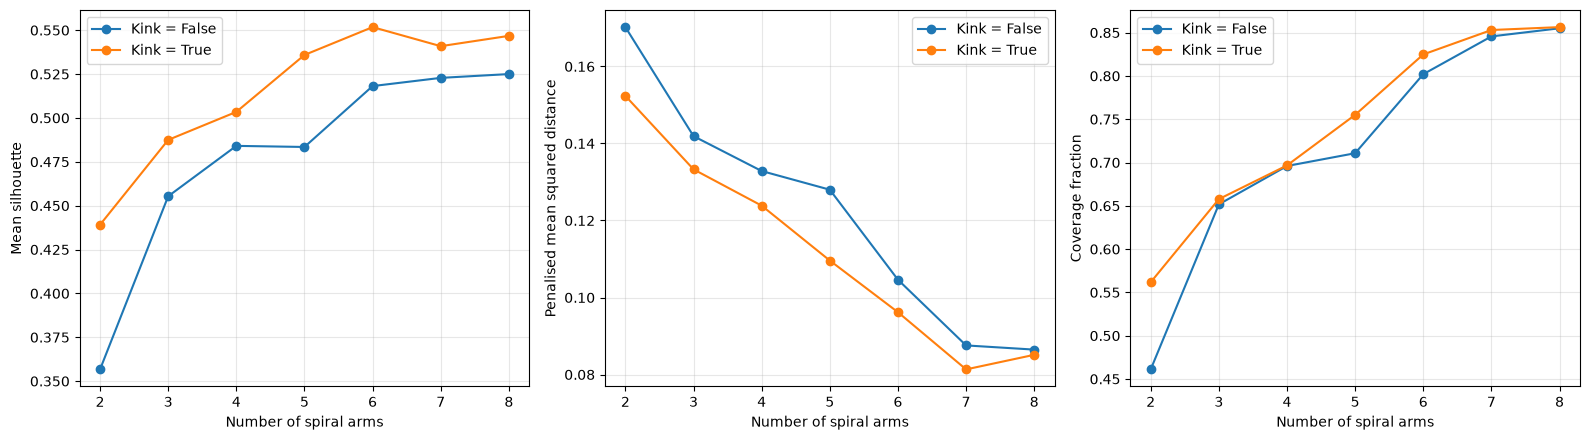

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

metrics = [
    ("coverage_adjusted_silhouette", "Mean silhouette"),
    ("MSE_penalised", "Penalised mean squared distance"),
    ("coverage", "Coverage fraction")
]

for ax, (metric, ylabel) in zip(axes, metrics):

    for kink, group in comparison_df.groupby("kink"):

        group = group.sort_values("n_arms")

        ax.plot(
            group["n_arms"],
            group[metric],
            marker="o",
            label=f"Kink = {kink}"
        )

    ax.set_xlabel("Number of spiral arms")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

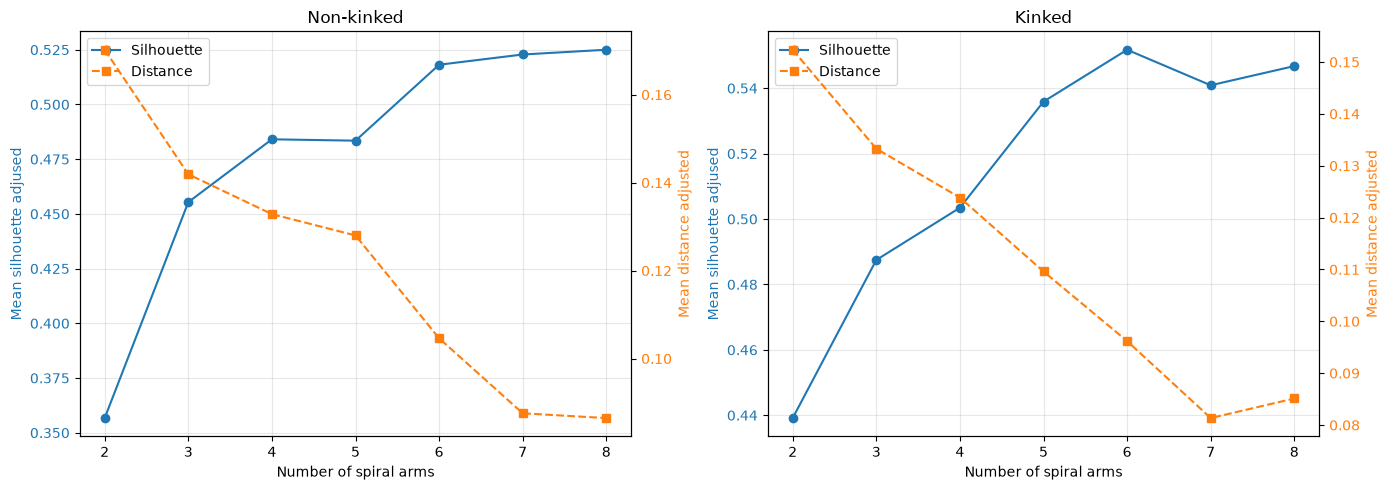

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)

for ax1, kink in zip(axes, [False, True]):

    group = comparison_df[
        comparison_df["kink"] == kink
    ].sort_values("n_arms")

    ax2 = ax1.twinx()

    # Mean silhouette (left axis)
    ax1.plot(
        group["n_arms"],
        group["coverage_adjusted_silhouette"],
        marker="o",
        color="tab:blue",
        label="Silhouette"
    )

    # Coverage fraction (right axis)
    ax2.plot(
        group["n_arms"],
        group["MSE_penalised"],
        marker="s",
        linestyle="--",
        color="tab:orange",
        label="Distance"
    )

    ax1.set_title("Kinked" if kink else "Non-kinked")
    ax1.set_xlabel("Number of spiral arms")
    ax1.set_ylabel("Mean silhouette adjused", color="tab:blue")
    ax2.set_ylabel("Mean distance adjusted", color="tab:orange")

    ax1.tick_params(axis="y", labelcolor="tab:blue")
    ax2.tick_params(axis="y", labelcolor="tab:orange")

    ax1.set_xticks(group["n_arms"])
    ax1.grid(alpha=0.3)

    # Combined legend
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")

plt.tight_layout()
plt.show()